In [1]:
# Extraction of zip files 

import shutil
import gzip
import csv
from pathlib import Path

# My directions
percorso_base = Path(r"C:\Users\vella\Desktop\tirocinio\Dataset\TEST_SET")
cartella_sorgente = percorso_base / "TEST_A_Normal"

cartella_slices = percorso_base / "slices_Normal"
cartella_masks = percorso_base / "masks_Normal"
cartella_slices.mkdir(parents=True, exist_ok=True)
cartella_masks.mkdir(parents=True, exist_ok=True)

# CVS file for mapping patients 
file_mapping = percorso_base / "mapping_pazienti_val.csv"

# pazienti_ok = 0
# lista_mapping = []
# indice = 1  # Initialize the index here

# print("Inizio estrazione e anonimizzazione dei file...\n")

# # iteration for patients counting (removed enumerate)
# for cartella_paziente in cartella_sorgente.iterdir():
#     if cartella_paziente.is_dir():
#         nome_originale = cartella_paziente.name
        
#         # anonimus name 
#         nuovo_nome = f"subject_{indice}"
        
#         path_file_ct = cartella_paziente / "CT.nii.gz"
#         path_file_mask = cartella_paziente / "Mask.nii.gz"
        
#         # final destination paths
#         dest_ct = cartella_slices / f"slice_{nuovo_nome}.nii"
#         dest_mask = cartella_masks / f"mask_{nuovo_nome}.nii"
        
#         if path_file_ct.exists() and path_file_mask.exists():
#             try:
#                 with gzip.open(path_file_ct, 'rb') as f_in:
#                     with open(dest_ct, 'wb') as f_out:
#                         shutil.copyfileobj(f_in, f_out)
                
#                 with gzip.open(path_file_mask, 'rb') as f_in:
#                     with open(dest_mask, 'wb') as f_out:
#                         shutil.copyfileobj(f_in, f_out)
                        
#                 # print(f" {nome_originale} -> convertito in -> {nuovo_nome}")
                
#                 # saving the mapping 
#                 lista_mapping.append([nuovo_nome, nome_originale])
#                 pazienti_ok += 1
                
#                 # Increment the index ONLY after a successful extraction
#                 indice += 1
                
#             except Exception as e:
#                 print(f" Errore durante l'estrazione di {nome_originale}: {e}")
#         else:
#             print(f" {nome_originale}: Impossibile trovare i file .nii.gz originali")

# # CVS file creation
# with open(file_mapping, mode='w', newline='', encoding='utf-8') as f_csv:
#     writer = csv.writer(f_csv)
#     writer.writerow(["ID_Anonimo", "Cartella_Originale"])
#     writer.writerows(lista_mapping)

# print(f" {pazienti_ok} pazienti pronti in formato subject_X.nii.")
# print(f"Mappa dei nomi salvata in: {file_mapping}")

In [2]:
import numpy as np
import nibabel as nib

print(" Checking structural and categorical integrity of target segmentation masks...\n")

anomalies_count = 0
EXPECTED_LABELS = {0, 1, 2}

# Target processed masks
for mask_path in cartella_masks.glob("*.nii.gz"):
    # 1. Load raw voxel data and cast to integer to avoid 0.0 vs 0 issues
    mask_data = nib.load(mask_path).get_fdata()
    mask_data = np.round(mask_data).astype(int) 
    
    # 2. Extract unique numerical values within this specific volume/slice
    unique_values = np.unique(mask_data)
    actual_labels = set(unique_values)
    
    # 3. FIX: Check if there are any labels OUTSIDE of {0, 1, 2}
    # We use issubset() because a mask with only {0, 1} is perfectly valid!
    if actual_labels != EXPECTED_LABELS:
        print(f" Label Anomaly detected in {mask_path.name}: Found values {unique_values}")
        anomalies_count += 1

print("--------------------------------------------------")
if anomalies_count == 0:
    print("Integrity Check Passed: All masks contain strictly valid categorical values [0, 1, 2].")
else:
    print(f"Integrity Check Failed: Found {anomalies_count} anomalous mask files requiring remediation.")

 Checking structural and categorical integrity of target segmentation masks...

--------------------------------------------------
Integrity Check Passed: All masks contain strictly valid categorical values [0, 1, 2].


In [3]:
import nibabel as nib
import numpy as np
from pathlib import Path

# Paths to your extracted 3D files
cartella_slices = Path(r"C:\Users\vella\Desktop\tirocinio\Dataset\TEST_SET\slices_Normal")
cartella_masks = Path(r"C:\Users\vella\Desktop\tirocinio\Dataset\TEST_SET\masks_Normal")

# print("Intelligently converting 3D volumes into annotated 2D slices (512, 512, 1)...")

# for ct_path in cartella_slices.glob("*.nii"):
#     # Find the corresponding mask file
#     mask_path = cartella_masks / ct_path.name.replace("slice_", "mask_")
    
#     if mask_path.exists():
#         # Load both CT and Mask
#         ct_img = nib.load(ct_path)
#         mask_img = nib.load(mask_path)
        
#         ct_data = ct_img.get_fdata()
#         # Cast mask to integer to avoid floating point issues
#         mask_data = np.round(mask_img.get_fdata()).astype(int)
        
#         # Check if it is a 3D volume (Z > 1)
#         if len(ct_data.shape) == 3 and ct_data.shape[2] > 1:
            
#             # --- INTELLIGENT SLICE SELECTION ---
#             z_idx = -1 
            
#             # Scan through the Z-axis (depth) to find the slice with the annotations
#             for z in range(mask_data.shape[2]):
#                 # Check if this slice contains Class 1 (Abdominals) or Class 2 (Psoas)
#                 if np.any(mask_data[:, :, z] == 1) or np.any(mask_data[:, :, z] == 2):
#                     z_idx = z
#                     break # We found the L3 slice! Stop searching.
            
#             if z_idx != -1:
#                 # Extract the specific 2D slice, keeping the dimension format (512, 512, 1)
#                 ct_2d = ct_data[:, :, z_idx : z_idx + 1]
#                 mask_2d = mask_data[:, :, z_idx : z_idx + 1]
                
#                 # Save them back, overwriting the heavy 3D files with the lightweight 2D files
#                 new_ct_img = nib.Nifti1Image(ct_2d, ct_img.affine, ct_img.header)
#                 new_mask_img = nib.Nifti1Image(mask_2d, mask_img.affine, mask_img.header)
                
#                 nib.save(new_ct_img, ct_path)
#                 nib.save(new_mask_img, mask_path)
                
#                 print(f"Converted {ct_path.name} -> Extracted annotated slice at Z={z_idx}. New shape: {ct_2d.shape}")
#             else:
#                 print(f" WARNING: No muscle annotations found in {mask_path.name}! Kept original file.")

# print("\nAll files successfully converted to 2D!")

In [5]:
import nibabel as nib

# Sostituisci con il percorso reale di una tua immagine
percorso = r"C:\Users\vella\Desktop\tirocinio\Dataset\TEST_SET\slices_Normal\slice_subject_3.nii"
percorso_2 = r"C:\Users\vella\Desktop\tirocinio\Dataset\TEST_SET\slices_Normal\slice_subject_29.nii"

print(f"Dimensioni: {nib.load(percorso).shape}")
print(f"Dimensioni: {nib.load(percorso_2).shape}")


Dimensioni: (512, 512, 1)
Dimensioni: (512, 512, 1)


In [6]:
import numpy as np
from scipy.ndimage import binary_erosion
from scipy.spatial import cKDTree

def get_boundary_coordinates(mask):
    """
    Extracts the pixel coordinates of the boundary of a binary mask
    using morphological erosion. Boundary = Original - Eroded.
    """
    eroded_mask = binary_erosion(mask)
    boundary = mask ^ eroded_mask 
    return np.argwhere(boundary)

def calculate_HD95_single_class_mm(y_true_binary, y_pred_binary, spacing_y_mm, spacing_x_mm):
    """
    Calculates the 95th Percentile Hausdorff Distance (HD95) for a single binary class in millimeters.
    This provides robust boundary error evaluation while ignoring extreme single-pixel outliers.
    """
    X = get_boundary_coordinates(y_true_binary)
    Y = get_boundary_coordinates(y_pred_binary)
    
    if len(X) == 0 and len(Y) == 0:
        return 0.0
    if len(X) == 0 or len(Y) == 0:
        return np.nan 
        
    # Convert pixel coordinates to physical millimeter space
    X_mm = X * np.array([spacing_y_mm, spacing_x_mm])
    Y_mm = Y * np.array([spacing_y_mm, spacing_x_mm])
    
    tree_X = cKDTree(X_mm)
    tree_Y = cKDTree(Y_mm)
    
    dist_X_to_Y, _ = tree_Y.query(X_mm)
    dist_Y_to_X, _ = tree_X.query(Y_mm)
    
    # Calculate the 95th percentile instead of the absolute maximum
    hd95_X = np.percentile(dist_X_to_Y, 95)
    hd95_Y = np.percentile(dist_Y_to_X, 95)
    
    hd95_mm = max(hd95_X, hd95_Y)
    
    return hd95_mm

def calculate_bAHD_single_class_mm(y_true_binary, y_pred_binary, spacing_y_mm, spacing_x_mm):
    """
    Calculates the Balanced Average Hausdorff Distance (bAHD) in millimeters.
    """
    X = get_boundary_coordinates(y_true_binary)
    Y = get_boundary_coordinates(y_pred_binary)
    
    if len(X) == 0 and len(Y) == 0:
        return 0.0
    if len(X) == 0 or len(Y) == 0:
        return np.nan 
        
    X_mm = X * np.array([spacing_y_mm, spacing_x_mm])
    Y_mm = Y * np.array([spacing_y_mm, spacing_x_mm])
    
    tree_X = cKDTree(X_mm)
    tree_Y = cKDTree(Y_mm)
    
    dist_X_to_Y, _ = tree_Y.query(X_mm)
    sum_dist_X = np.sum(dist_X_to_Y)
    
    dist_Y_to_X, _ = tree_X.query(Y_mm)
    sum_dist_Y = np.sum(dist_Y_to_X)
    
    bahd_mm = (sum_dist_X + sum_dist_Y) / (len(X) + len(Y))
    
    return bahd_mm

In [7]:
import os
import numpy as np
import nibabel as nib
import tensorflow as tf
from pathlib import Path

# Suppress warnings for clean output
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

# 1. SETUP PATHS FOR THE EXTERNAL DATASET
# This must be a completely independent folder of data
DIR_EXTERNAL_CT = Path(r"C:\Users\vella\Desktop\tirocinio\Dataset\TEST_SET\slices_Normal")
DIR_EXTERNAL_MASKS = Path(r"C:\Users\vella\Desktop\tirocinio\Dataset\TEST_SET\masks_Normal")

external_ct_files = sorted(list(DIR_EXTERNAL_CT.glob("*.nii")))
external_mask_files = sorted(list(DIR_EXTERNAL_MASKS.glob("*.nii")))

print(f"External Validation Cohort: {len(external_ct_files)} patients found.")

# 2. LOAD THE PRE-TRAINED PROTOTYPE
MODEL_PATH = "unet_sarcopenia_best.keras"
print(f"Loading weights from: {MODEL_PATH}")
model = tf.keras.models.load_model(MODEL_PATH, compile=False)

# 3. INITIALIZE TRACKING ARRAYS
ext_abdominals_dice, ext_psoas_dice = [], []
ext_abdominals_iou, ext_psoas_iou = [], []
ext_abdominals_bahd, ext_psoas_bahd = [], []
ext_abdominals_hd95, ext_psoas_hd95 = [], []

TARGET_SIZE = (256, 256)

print("\nExecuting Inference and Metric Calculation on External Cohort...")

# 4. EXTERNAL EVALUATION LOOP
for ct_path, mask_path in zip(external_ct_files, external_mask_files):
    
    # Load native NIfTI files
    nii_ct = nib.load(ct_path)
    nii_mask = nib.load(mask_path)
    
    original_data = np.squeeze(nii_ct.get_fdata())
    true_mask = np.squeeze(nii_mask.get_fdata())
    
    original_zooms = nii_ct.header.get_zooms()
    original_shape = original_data.shape
    
    # Preprocessing (HU Windowing & Normalization)
    HU_MIN, HU_MAX = -30.0, 150.0
    img_np = np.clip(original_data, HU_MIN, HU_MAX)
    img_np = (img_np - HU_MIN) / (HU_MAX - HU_MIN)
    
    # Resize for network
    img_tensor = tf.expand_dims(tf.convert_to_tensor(img_np, dtype=tf.float32), axis=-1)
    img_resized = tf.image.resize(img_tensor, TARGET_SIZE, method='bilinear').numpy()
    input_batch = np.expand_dims(img_resized, axis=0)
    
    # Neural Network Prediction
    preds = model.predict(input_batch, verbose=0)
    pred_mask_256 = np.argmax(preds, axis=-1)[0]
    
    # Restore prediction to native resolution via Nearest Neighbor
    pred_mask = tf.image.resize(
        np.expand_dims(pred_mask_256, axis=-1),
        original_shape[:2], 
        method='nearest'
    ).numpy().squeeze()
    
    # Physical spacing multipliers
    spacing_x_mm = original_zooms[0]
    spacing_y_mm = original_zooms[1]
    
    # --- EVALUATE ABDOMINALS (Class 1) ---
    true_abs = (true_mask == 1)
    pred_abs = (pred_mask == 1)
    
    intersection_abs = np.sum(true_abs & pred_abs)
    sum_abs = np.sum(true_abs) + np.sum(pred_abs)
    
    if sum_abs > 0:
        ext_abdominals_dice.append((2.0 * intersection_abs) / sum_abs)
        ext_abdominals_iou.append(intersection_abs / (sum_abs - intersection_abs))
        
    bahd_abs = calculate_bAHD_single_class_mm(true_abs, pred_abs, spacing_y_mm, spacing_x_mm)
    hd95_abs = calculate_HD95_single_class_mm(true_abs, pred_abs, spacing_y_mm, spacing_x_mm)
    if not np.isnan(bahd_abs): ext_abdominals_bahd.append(bahd_abs)
    if not np.isnan(hd95_abs): ext_abdominals_hd95.append(hd95_abs)

    # --- EVALUATE PSOAS (Class 2) ---
    true_psoas = (true_mask == 2)
    pred_psoas = (pred_mask == 2)
    
    intersection_psoas = np.sum(true_psoas & pred_psoas)
    sum_psoas = np.sum(true_psoas) + np.sum(pred_psoas)
    
    if sum_psoas > 0:
        ext_psoas_dice.append((2.0 * intersection_psoas) / sum_psoas)
        ext_psoas_iou.append(intersection_psoas / (sum_psoas - intersection_psoas))
        
    bahd_psoas = calculate_bAHD_single_class_mm(true_psoas, pred_psoas, spacing_y_mm, spacing_x_mm)
    hd95_psoas = calculate_HD95_single_class_mm(true_psoas, pred_psoas, spacing_y_mm, spacing_x_mm)
    if not np.isnan(bahd_psoas): ext_psoas_bahd.append(bahd_psoas)
    if not np.isnan(hd95_psoas): ext_psoas_hd95.append(hd95_psoas)

# 5. FINAL REPORTING
print("\n==================================================")
print("EXTERNAL VALIDATION COHORT RESULTS")
print("==================================================")
print(f"ABDOMINALS -> Dice: {np.mean(ext_abdominals_dice):.4f} | IoU: {np.mean(ext_abdominals_iou):.4f} | HD95: {np.mean(ext_abdominals_hd95):.2f} mm")
print(f"PSOAS      -> Dice: {np.mean(ext_psoas_dice):.4f} | IoU: {np.mean(ext_psoas_iou):.4f} | HD95: {np.mean(ext_psoas_hd95):.2f} mm")
print("==================================================")

External Validation Cohort: 30 patients found.
Loading weights from: unet_sarcopenia_best.keras

Executing Inference and Metric Calculation on External Cohort...

EXTERNAL VALIDATION COHORT RESULTS
ABDOMINALS -> Dice: 0.8653 | IoU: 0.7700 | HD95: 21.79 mm
PSOAS      -> Dice: 0.8671 | IoU: 0.7701 | HD95: 10.35 mm


In [9]:
import numpy as np
import pandas as pd
from IPython.display import display

# Define the helper function explicitly in this cell
def generate_statistics_table(metrics_dict, metric_name, unit=""):
    """Helper function to calculate standard descriptive statistics."""
    stats = []
    for class_name, data in metrics_dict.items():
        # Filter out any potential NaNs before calculating
        clean_data = [x for x in data if not np.isnan(x)]
        if not clean_data:
            continue
            
        stats.append({
            "Class": class_name,
            "Metric": metric_name,
            "Mean": np.mean(clean_data),
            "Median": np.median(clean_data),
            "SD (±)": np.std(clean_data),
            "Min": np.min(clean_data),
            "Max": np.max(clean_data),
            "Unit": unit
        })
    return pd.DataFrame(stats)

print("==================================================")
print(" INDEPENDENT COHORT: DESCRIPTIVE STATISTICS")
print("==================================================")

# 1. Volumetric Metrics (Dice & IoU)
dice_stats_ext = generate_statistics_table(
    {"Abdominals": ext_abdominals_dice, "Psoas": ext_psoas_dice}, "Dice"
)
iou_stats_ext = generate_statistics_table(
    {"Abdominals": ext_abdominals_iou, "Psoas": ext_psoas_iou}, "IoU"
)
volumetric_ext_df = pd.concat([dice_stats_ext, iou_stats_ext]).set_index(["Metric", "Class"])

# 2. Boundary Metrics (bAHD & HD95)
bahd_stats_ext = generate_statistics_table(
    {"Abdominals": ext_abdominals_bahd, "Psoas": ext_psoas_bahd}, "bAHD", "mm"
)
hd95_stats_ext = generate_statistics_table(
    {"Abdominals": ext_abdominals_hd95, "Psoas": ext_psoas_hd95}, "HD95", "mm"
)
boundary_ext_df = pd.concat([bahd_stats_ext, hd95_stats_ext]).set_index(["Metric", "Class"])

# Display the tables nicely rounded
display(volumetric_ext_df.round(4))
display(boundary_ext_df.round(2))

 INDEPENDENT COHORT: DESCRIPTIVE STATISTICS


Mean  Median  SD (±)     Min     Max Unit
Metric Class                                                  
Dice   Abdominals  0.8653  0.8911  0.0770  0.6393  0.9396     
       Psoas       0.8671  0.8843  0.0599  0.7432  0.9485     
IoU    Abdominals  0.7700  0.8036  0.1092  0.4698  0.8862     
       Psoas       0.7701  0.7926  0.0905  0.5913  0.9020

Mean  Median  SD (±)   Min    Max Unit
Metric Class                                              
bAHD   Abdominals   3.02    2.17    2.23  0.78   9.81   mm
       Psoas        2.56    1.91    1.96  0.94   9.79   mm
HD95   Abdominals  21.79   15.67   18.19  3.23  78.22   mm
       Psoas       10.35    6.18    9.78  2.52  43.23   mm

In [10]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
import numpy as np

def crop_to_body(ct_slice, mask_true, mask_pred, margin=30):
    """
    Dynamically crops the image to the patient's body contour by removing background air,
    enhancing the visualization of the target muscle groups.
    """
    body_pixels = ct_slice > 0.05 
    rows = np.any(body_pixels, axis=1)
    cols = np.any(body_pixels, axis=0)
    
    if not np.any(rows) or not np.any(cols):
        return ct_slice, mask_true, mask_pred 
        
    rmin, rmax = np.where(rows)[0][[0, -1]]
    cmin, cmax = np.where(cols)[0][[0, -1]]
    
    rmin, rmax = max(0, rmin-margin), min(ct_slice.shape[0], rmax+margin)
    cmin, cmax = max(0, cmin-margin), min(ct_slice.shape[1], cmax+margin)
    
    return ct_slice[rmin:rmax, cmin:cmax], mask_true[rmin:rmax, cmin:cmax], mask_pred[rmin:rmax, cmin:cmax]

def plot_step2_segmentation(ct_slice, true_mask, pred_mask, slice_idx=1):
    
    ct_slice = np.squeeze(ct_slice)
    true_mask = np.squeeze(true_mask)
    pred_mask = np.squeeze(pred_mask)
    
    ct_crop, true_crop, pred_crop = crop_to_body(ct_slice, true_mask, pred_mask)

    # Define strict colors: Background (None), Abdominals (Blue), Psoas (Green)
    cmap_masks = mcolors.ListedColormap(['none', 'red', 'green']) 
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 6), dpi=300)
    fig.patch.set_facecolor('white') 
    
    # 1. Original CT Scan
    axes[0].imshow(ct_crop, cmap='gray')
    axes[0].set_title('Original CT Scan', fontsize=14, pad=10)
    axes[0].axis('off')

    # 2. Ground Truth 
    axes[1].imshow(ct_crop, cmap='gray')
    mask_true_masked = np.ma.masked_where(true_crop == 0, true_crop)
    # vmin=0, vmax=2 strictly locks the color mapping to the 3 anatomical classes
    axes[1].imshow(mask_true_masked, cmap=cmap_masks, alpha=0.6, vmin=0, vmax=2)
    axes[1].set_title('Ground Truth (Clinical)', fontsize=14, pad=10)
    axes[1].axis('off')

    # 3. AI Prediction
    axes[2].imshow(ct_crop, cmap='gray')
    mask_pred_masked = np.ma.masked_where(pred_crop == 0, pred_crop)
    axes[2].imshow(mask_pred_masked, cmap=cmap_masks, alpha=0.6, vmin=0, vmax=2)
    axes[2].set_title('U-Net Prototype Prediction', fontsize=14, pad=10)
    axes[2].axis('off')

    legend_elements = [
        Patch(facecolor='red', alpha=0.6, label='Abdominals (Class 1)'),
        Patch(facecolor='green', alpha=0.6, label='Psoas (Class 2)')
    ]
    fig.legend(handles=legend_elements, loc='lower center', ncol=2, bbox_to_anchor=(0.5, 0.05), fontsize=12, frameon=False)

    plt.tight_layout(rect=[0, 0.12, 1, 1]) 
    # plt.savefig(f"thesis_TestSet_Segmentation_Slice{slice_idx}.png", bbox_inches='tight', facecolor='white')
    plt.show()

Ricerca del miglior caso nella Independent Cohort e calcolo metriche complete...

 MIGLIOR CASO INDEPENDENT COHORT (slice_subject_28.nii)
ADDOMINALI -> Dice: 0.9347 | IoU: 0.8774 | bAHD: 2.56 mm | HD95: 27.48 mm
PSOAS      -> Dice: 0.8784 | IoU: 0.7831 | bAHD: 2.03 mm | HD95: 6.11 mm


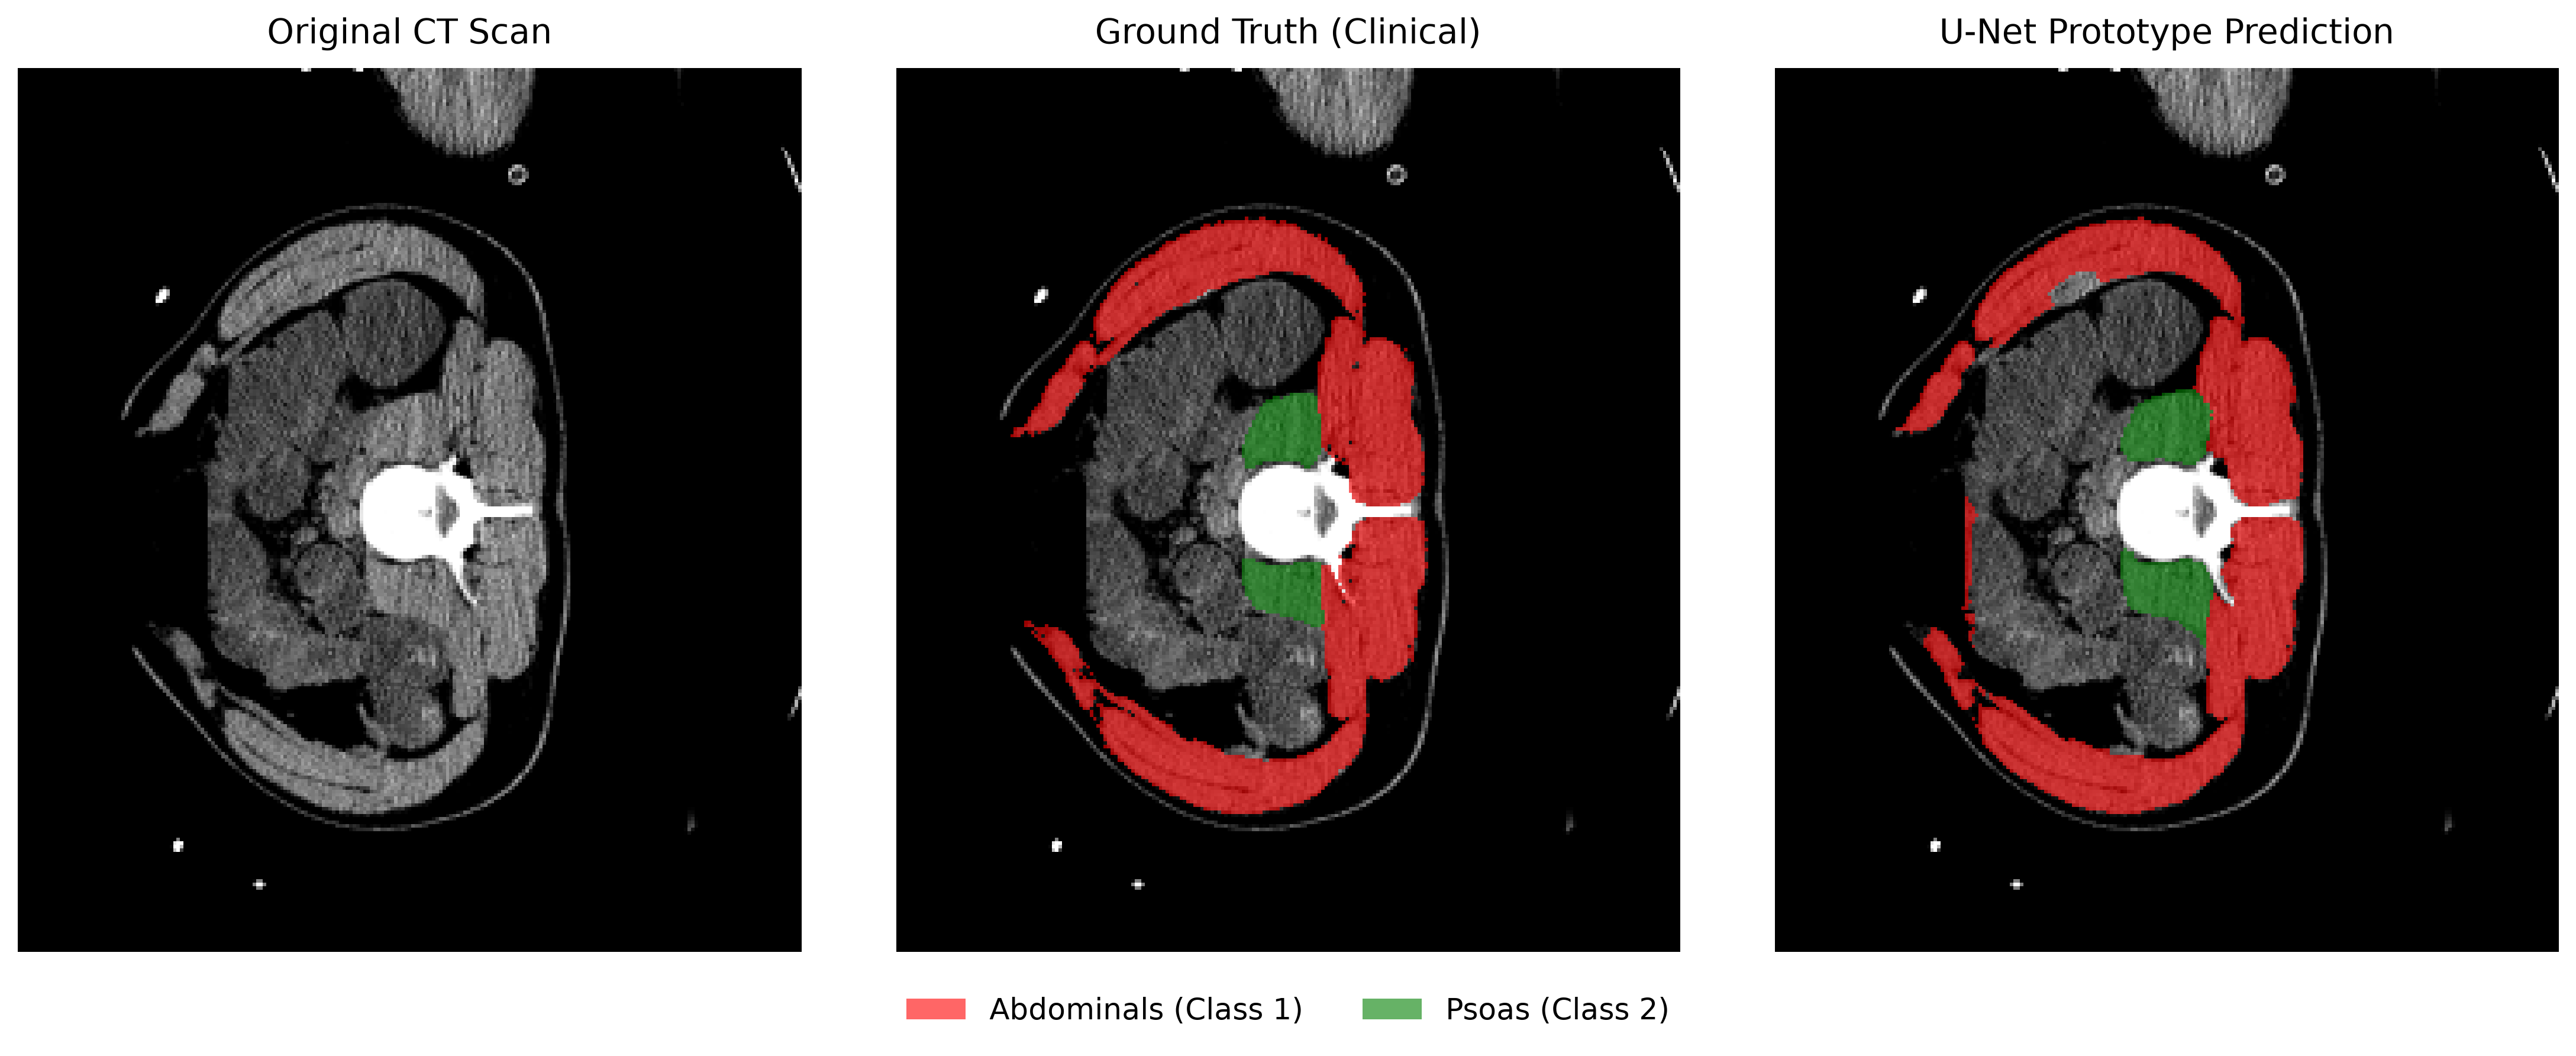

In [11]:
import numpy as np
import nibabel as nib
import tensorflow as tf

print("Ricerca del miglior caso nella Independent Cohort e calcolo metriche complete...")

migliori_casi_external = []
TARGET_SIZE = (256, 256)
HU_MIN, HU_MAX = -30.0, 150.0

# 1. Ricerca Veloce del Vincitore
for ct_path, mask_path in zip(external_ct_files, external_mask_files):
    nii_ct = nib.load(ct_path)
    nii_mask = nib.load(mask_path)
    original_data = np.squeeze(nii_ct.get_fdata())
    true_mask = np.squeeze(nii_mask.get_fdata())
    
    img_np = np.clip(original_data, HU_MIN, HU_MAX)
    img_np = (img_np - HU_MIN) / (HU_MAX - HU_MIN)
    img_tensor = tf.expand_dims(tf.convert_to_tensor(img_np, dtype=tf.float32), axis=-1)
    img_resized = tf.image.resize(img_tensor, TARGET_SIZE, method='bilinear').numpy()
    
    preds = model.predict(np.expand_dims(img_resized, axis=0), verbose=0)
    pred_mask_256 = np.argmax(preds, axis=-1)[0]
    
    pred_mask = tf.image.resize(np.expand_dims(pred_mask_256, axis=-1), original_data.shape[:2], method='nearest').numpy().squeeze()
    
    intersection = np.sum((true_mask > 0) & (pred_mask > 0))
    sum_masks = np.sum(true_mask > 0) + np.sum(pred_mask > 0)
    
    if sum_masks > 0:
        dice_score = (2.0 * intersection) / sum_masks
        migliori_casi_external.append((dice_score, ct_path, mask_path, img_resized, pred_mask_256))

migliori_casi_external.sort(key=lambda x: x[0], reverse=True)
best_ext_dice, best_ct_path, best_mask_path, best_ext_img, best_ext_pred = migliori_casi_external[0]

# 2. Ricarico il vincitore per estrarre la spaziatura reale (mm) e calcolare le metriche fisiche
nii_ct = nib.load(best_ct_path)
nii_mask = nib.load(best_mask_path)
true_mask = np.squeeze(nii_mask.get_fdata())
original_shape = true_mask.shape
original_zooms = nii_ct.header.get_zooms()

pred_mask = tf.image.resize(np.expand_dims(best_ext_pred, axis=-1), original_shape[:2], method='nearest').numpy().squeeze()

spacing_x_mm = original_zooms[0]
spacing_y_mm = original_zooms[1]

def calc_ext_metrics(y_true, y_pred, class_val, spacing_y, spacing_x):
    t_mask = (y_true == class_val)
    p_mask = (y_pred == class_val)
    inter = np.sum(t_mask & p_mask)
    sum_m = np.sum(t_mask) + np.sum(p_mask)
    dice = (2.0 * inter) / sum_m if sum_m > 0 else 0
    iou = inter / (sum_m - inter) if (sum_m - inter) > 0 else 0
    bahd = calculate_bAHD_single_class_mm(t_mask, p_mask, spacing_y, spacing_x)
    hd95 = calculate_HD95_single_class_mm(t_mask, p_mask, spacing_y, spacing_x)
    return dice, iou, bahd, hd95

ext_dice_abs, ext_iou_abs, ext_bahd_abs, ext_hd95_abs = calc_ext_metrics(true_mask, pred_mask, 1, spacing_y_mm, spacing_x_mm)
ext_dice_psoas, ext_iou_psoas, ext_bahd_psoas, ext_hd95_psoas = calc_ext_metrics(true_mask, pred_mask, 2, spacing_y_mm, spacing_x_mm)

print("\n==================================================")
print(f" MIGLIOR CASO INDEPENDENT COHORT ({best_ct_path.name})")
print("==================================================")
print(f"ADDOMINALI -> Dice: {ext_dice_abs:.4f} | IoU: {ext_iou_abs:.4f} | bAHD: {ext_bahd_abs:.2f} mm | HD95: {ext_hd95_abs:.2f} mm")
print(f"PSOAS      -> Dice: {ext_dice_psoas:.4f} | IoU: {ext_iou_psoas:.4f} | bAHD: {ext_bahd_psoas:.2f} mm | HD95: {ext_hd95_psoas:.2f} mm")
print("==================================================")

plot_step2_segmentation(
    ct_slice=best_ext_img, 
    true_mask=tf.image.resize(np.expand_dims(true_mask, axis=-1), TARGET_SIZE, method='nearest').numpy().squeeze(), 
    pred_mask=best_ext_pred, 
    slice_idx=f"BestExternal_{best_ct_path.name.replace('.nii','')}" 
)

Ricerca dei casi clinici con il peggior errore spaziale (Max HD95) e calcolo metriche complete...

 I 7 CASI PEGGIORI (WORST-CASE SCENARIOS)

#1 - slice_subject_4.nii | Errore Massimo HD95: 78.22 mm
   ADDOMINALI -> Dice: 0.8206 | IoU: 0.6958 | bAHD: 9.81 mm | HD95: 78.22 mm
   PSOAS      -> Dice: 0.8058 | IoU: 0.6747 | bAHD: 6.44 mm | HD95: 11.28 mm


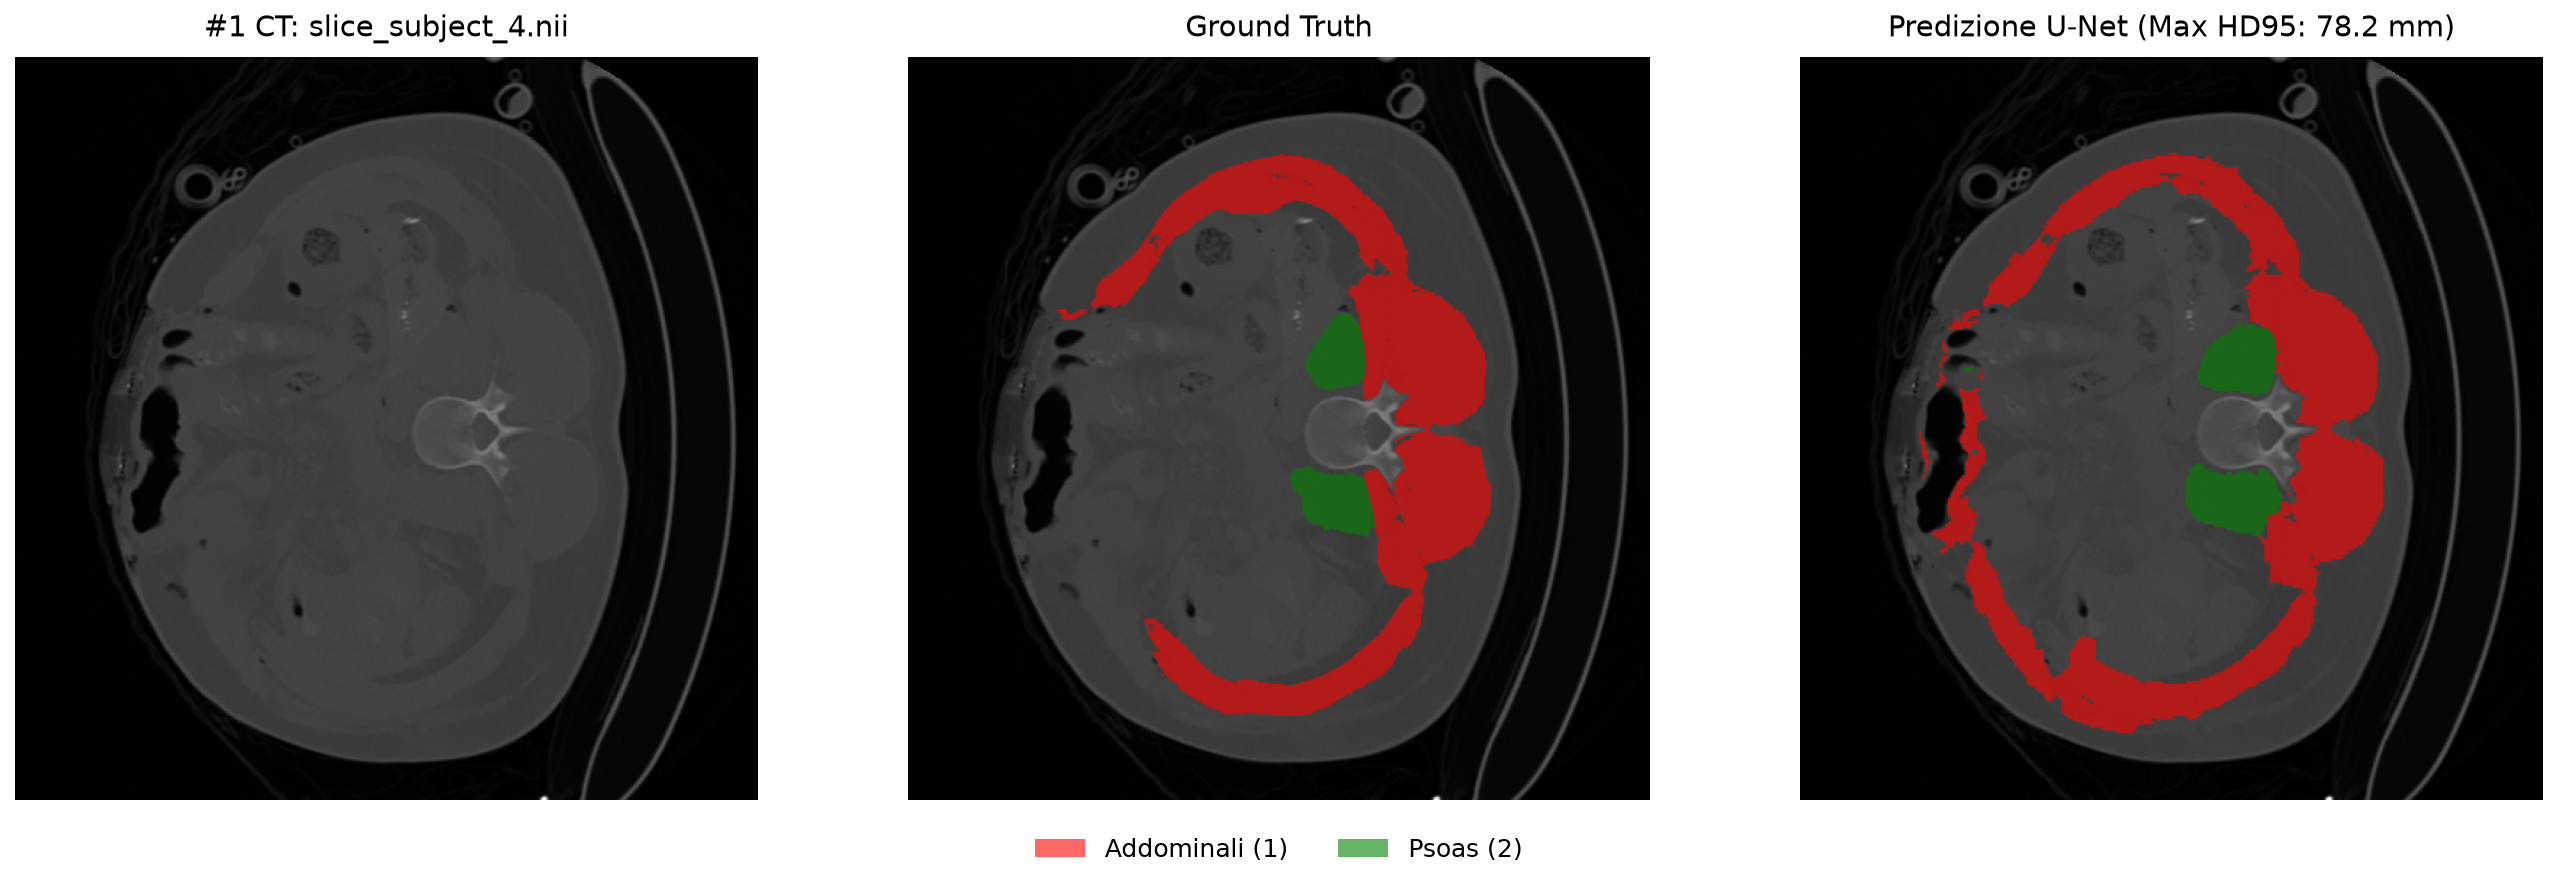


#2 - slice_subject_17.nii | Errore Massimo HD95: 53.39 mm
   ADDOMINALI -> Dice: 0.8551 | IoU: 0.7469 | bAHD: 5.71 mm | HD95: 53.39 mm
   PSOAS      -> Dice: 0.7619 | IoU: 0.6153 | bAHD: 9.79 mm | HD95: 43.23 mm


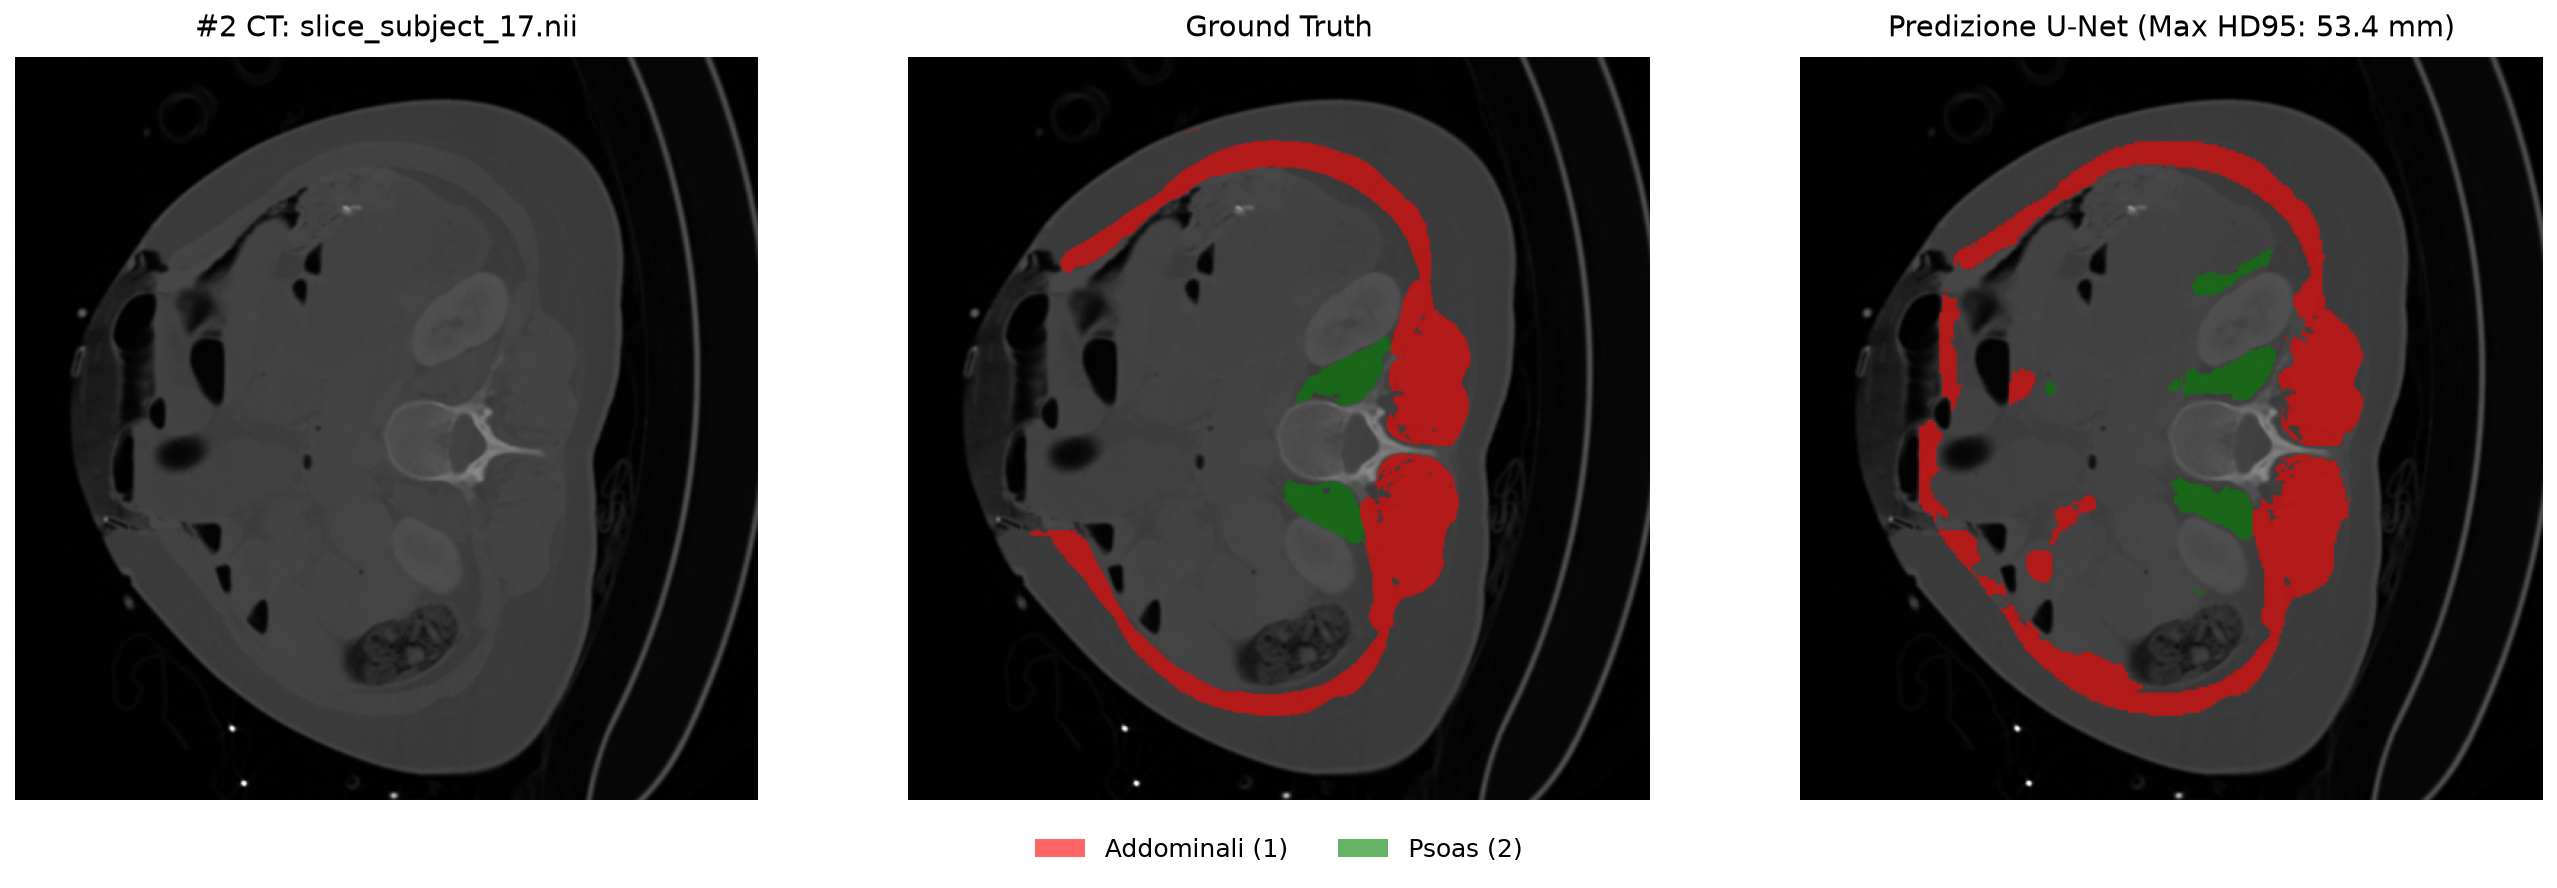


#3 - slice_subject_10.nii | Errore Massimo HD95: 49.97 mm
   ADDOMINALI -> Dice: 0.6973 | IoU: 0.5353 | bAHD: 7.72 mm | HD95: 49.97 mm
   PSOAS      -> Dice: 0.8784 | IoU: 0.7832 | bAHD: 2.49 mm | HD95: 8.68 mm


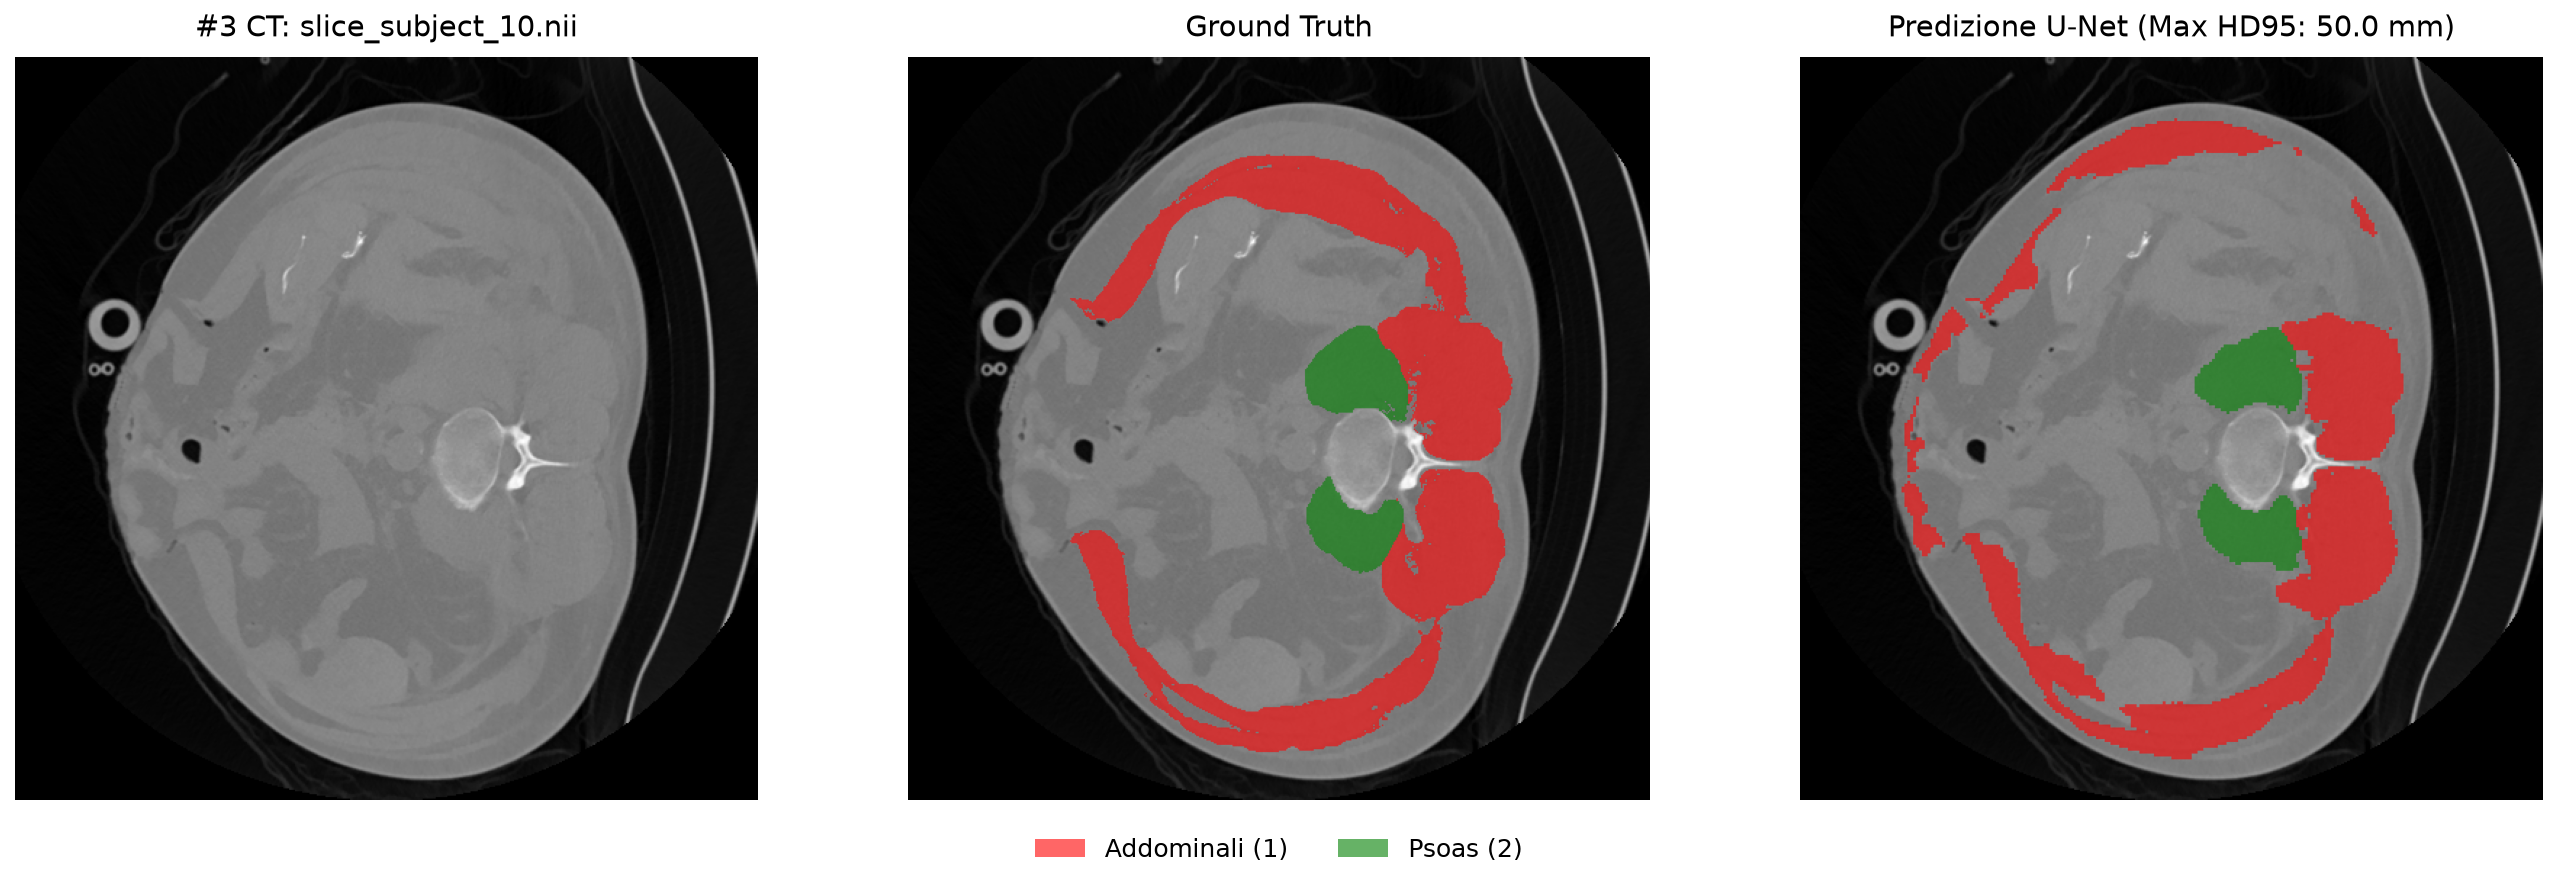


#4 - slice_subject_5.nii | Errore Massimo HD95: 49.27 mm
   ADDOMINALI -> Dice: 0.6393 | IoU: 0.4698 | bAHD: 8.36 mm | HD95: 49.27 mm
   PSOAS      -> Dice: 0.7941 | IoU: 0.6586 | bAHD: 3.96 mm | HD95: 14.91 mm


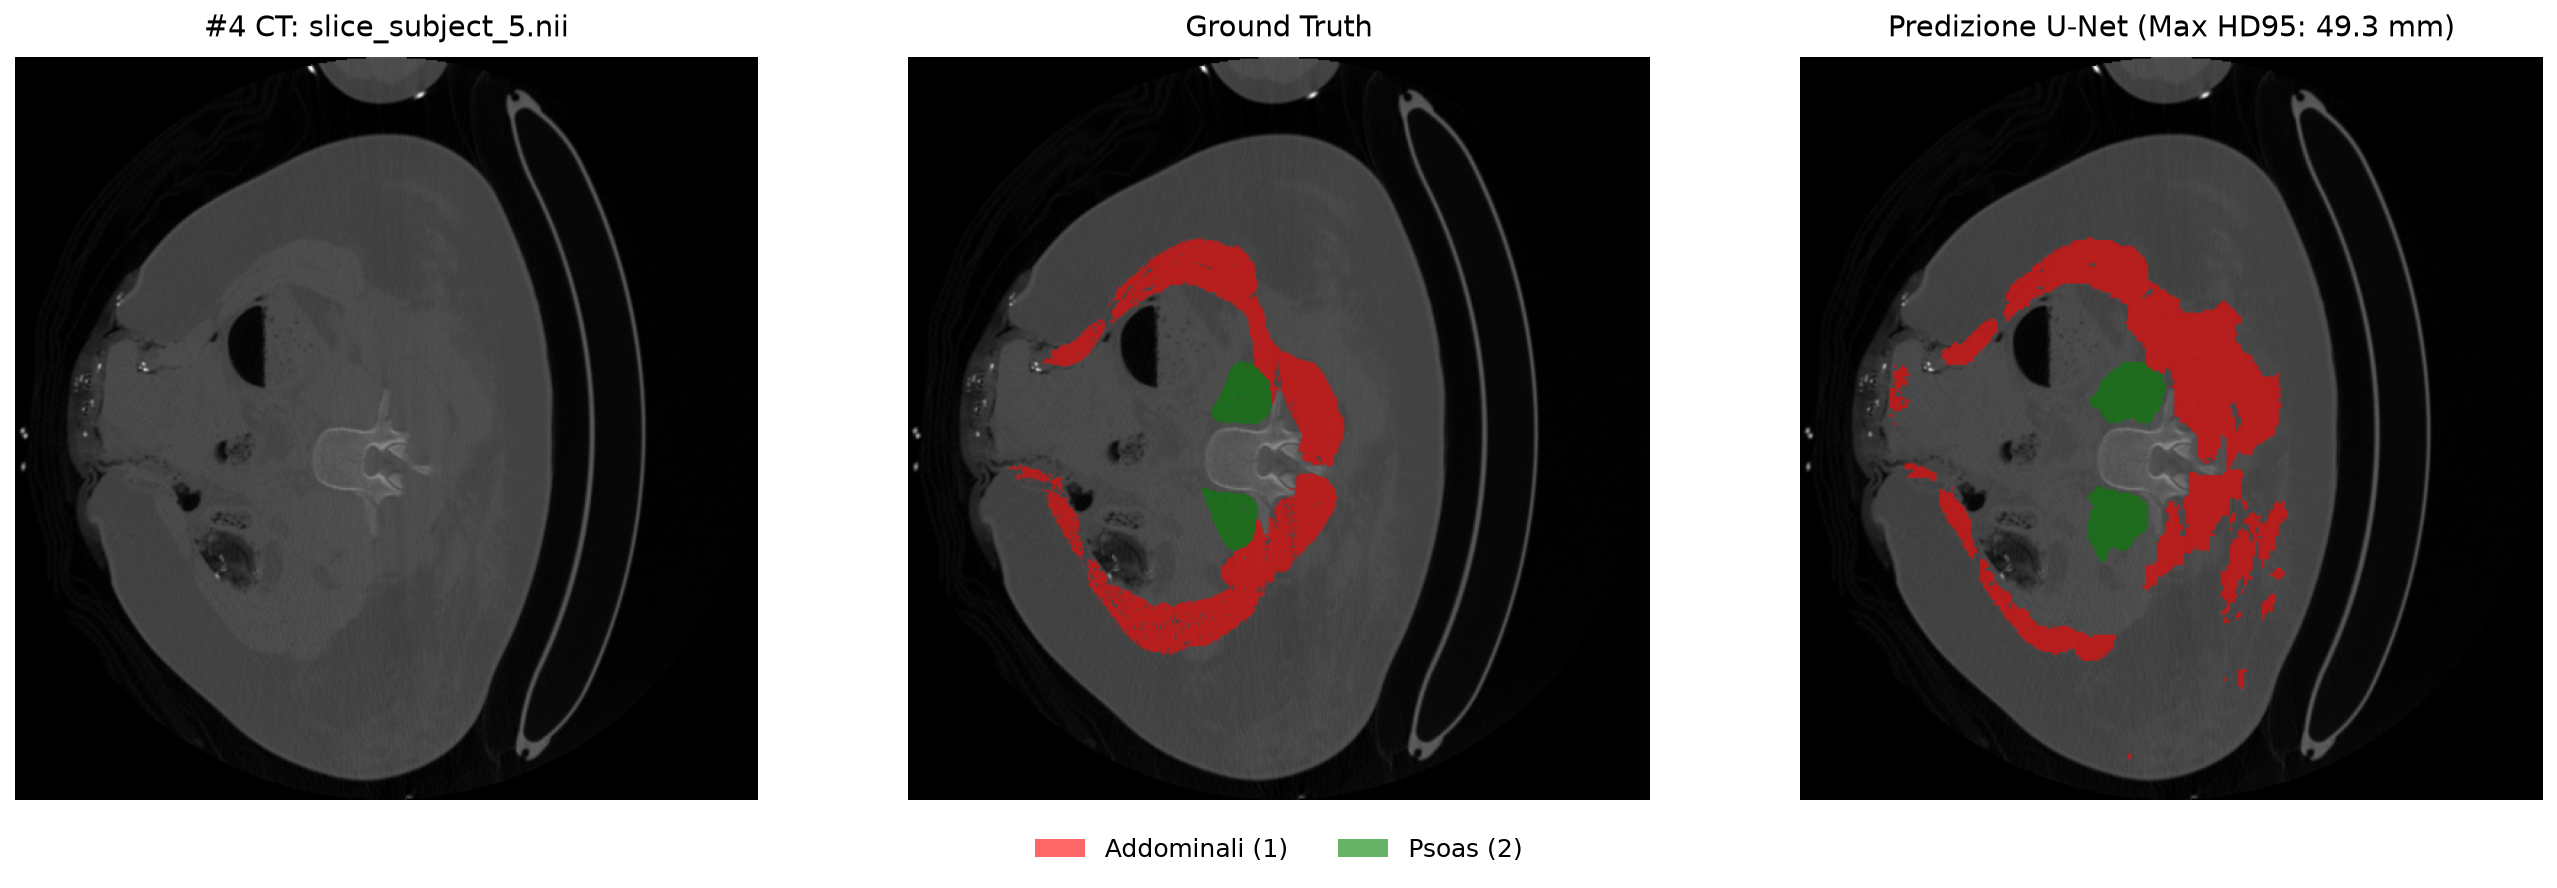


#5 - slice_subject_20.nii | Errore Massimo HD95: 49.01 mm
   ADDOMINALI -> Dice: 0.8843 | IoU: 0.7926 | bAHD: 3.63 mm | HD95: 49.01 mm
   PSOAS      -> Dice: 0.9327 | IoU: 0.8738 | bAHD: 0.95 mm | HD95: 3.91 mm


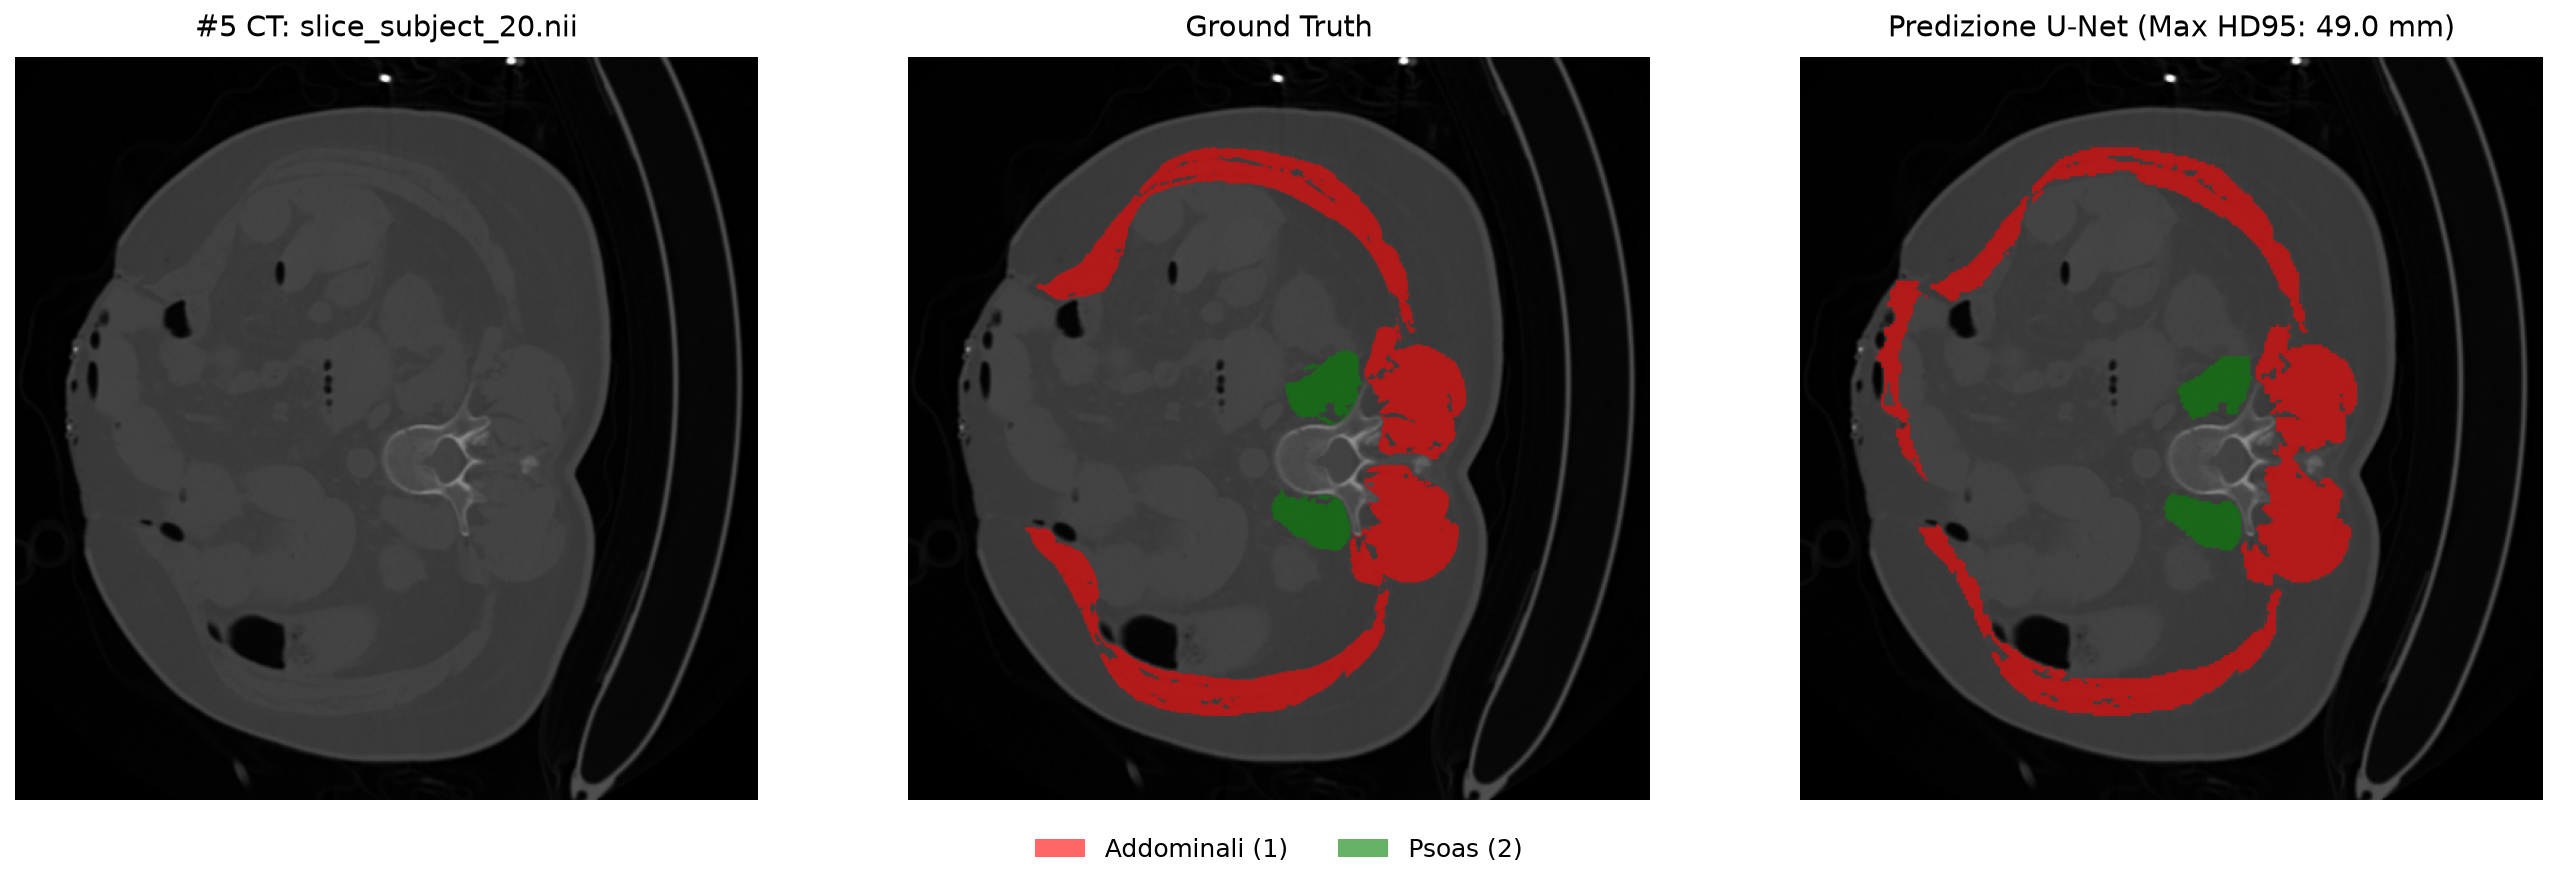


#6 - slice_subject_23.nii | Errore Massimo HD95: 38.69 mm
   ADDOMINALI -> Dice: 0.9113 | IoU: 0.8370 | bAHD: 3.39 mm | HD95: 38.69 mm
   PSOAS      -> Dice: 0.9187 | IoU: 0.8497 | bAHD: 1.79 mm | HD95: 6.25 mm


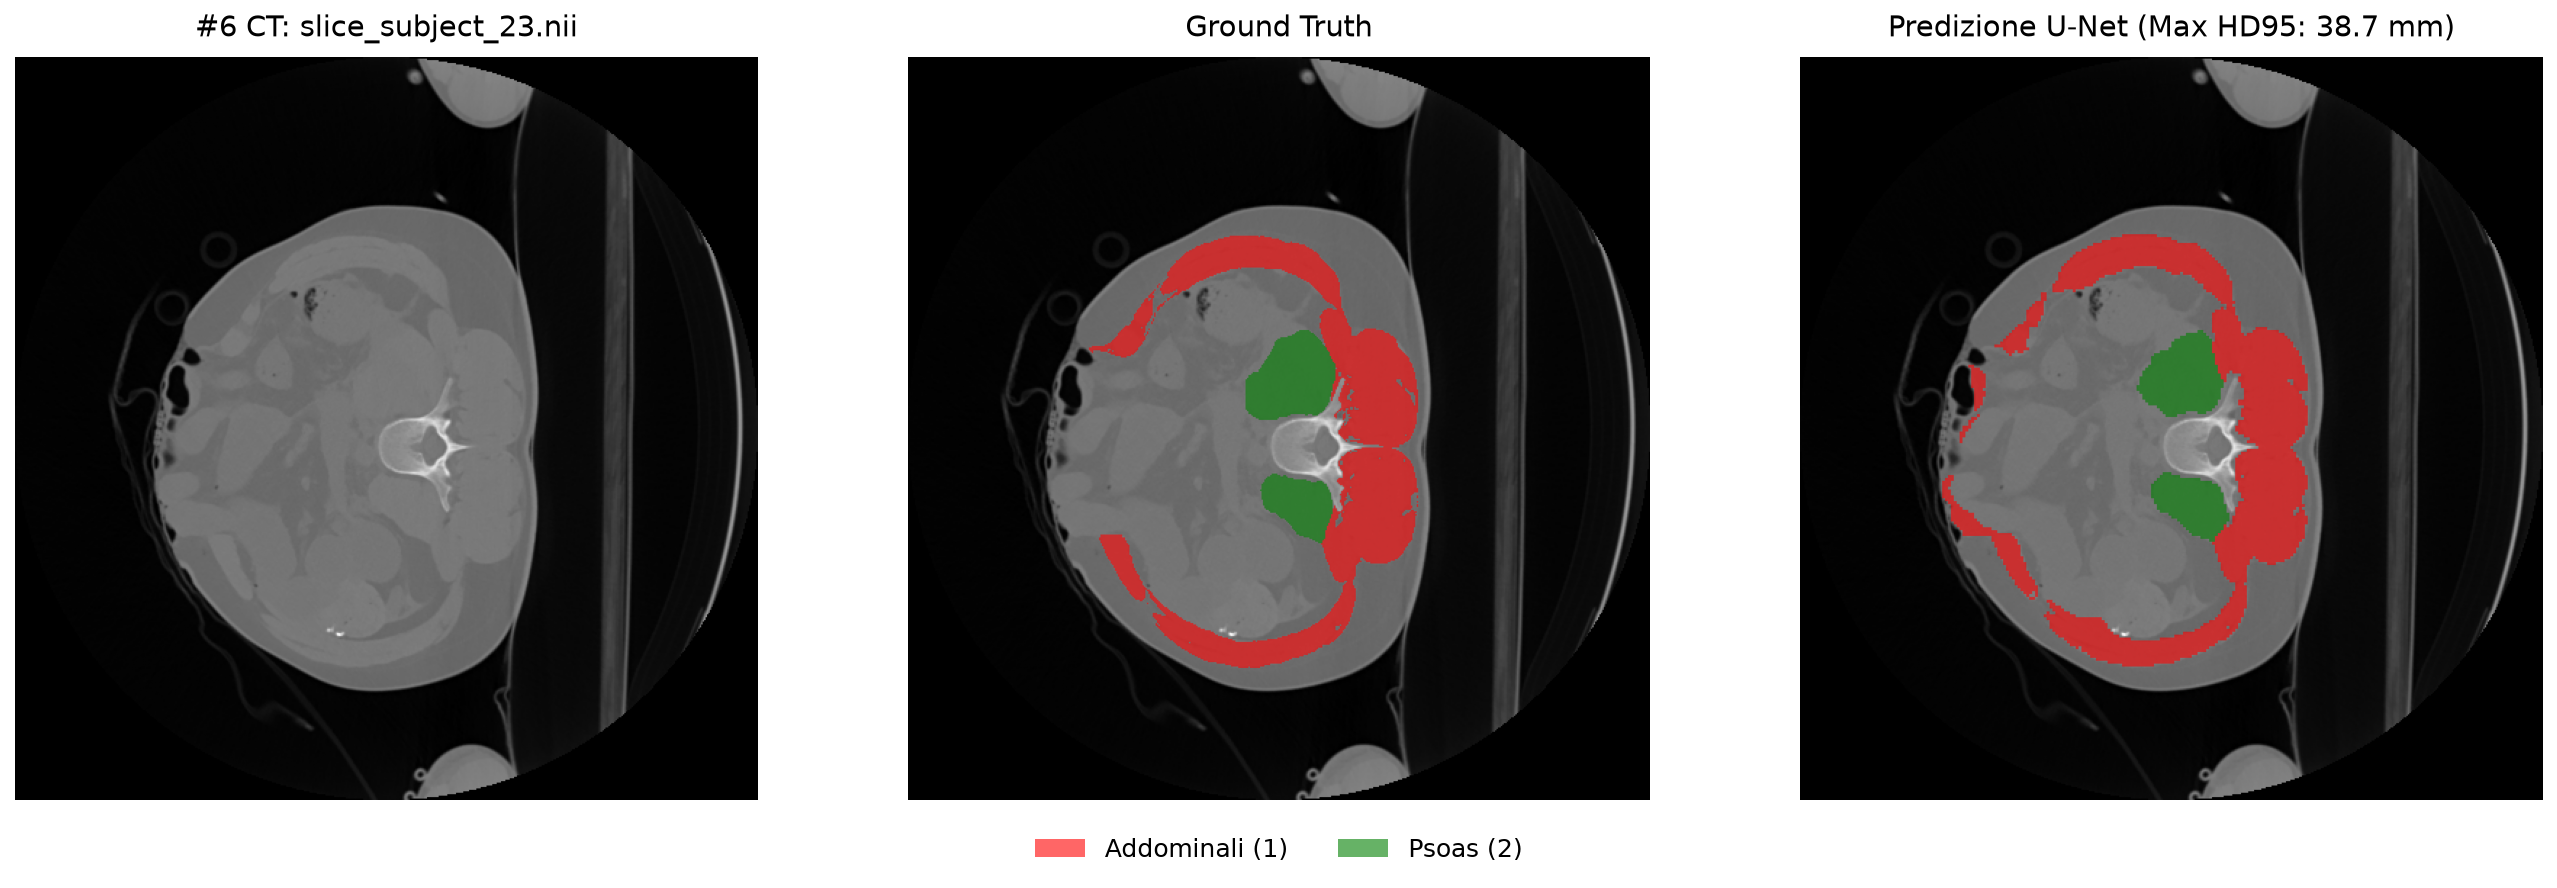


#7 - slice_subject_24.nii | Errore Massimo HD95: 36.13 mm
   ADDOMINALI -> Dice: 0.8609 | IoU: 0.7558 | bAHD: 2.54 mm | HD95: 11.39 mm
   PSOAS      -> Dice: 0.8116 | IoU: 0.6829 | bAHD: 4.89 mm | HD95: 36.13 mm


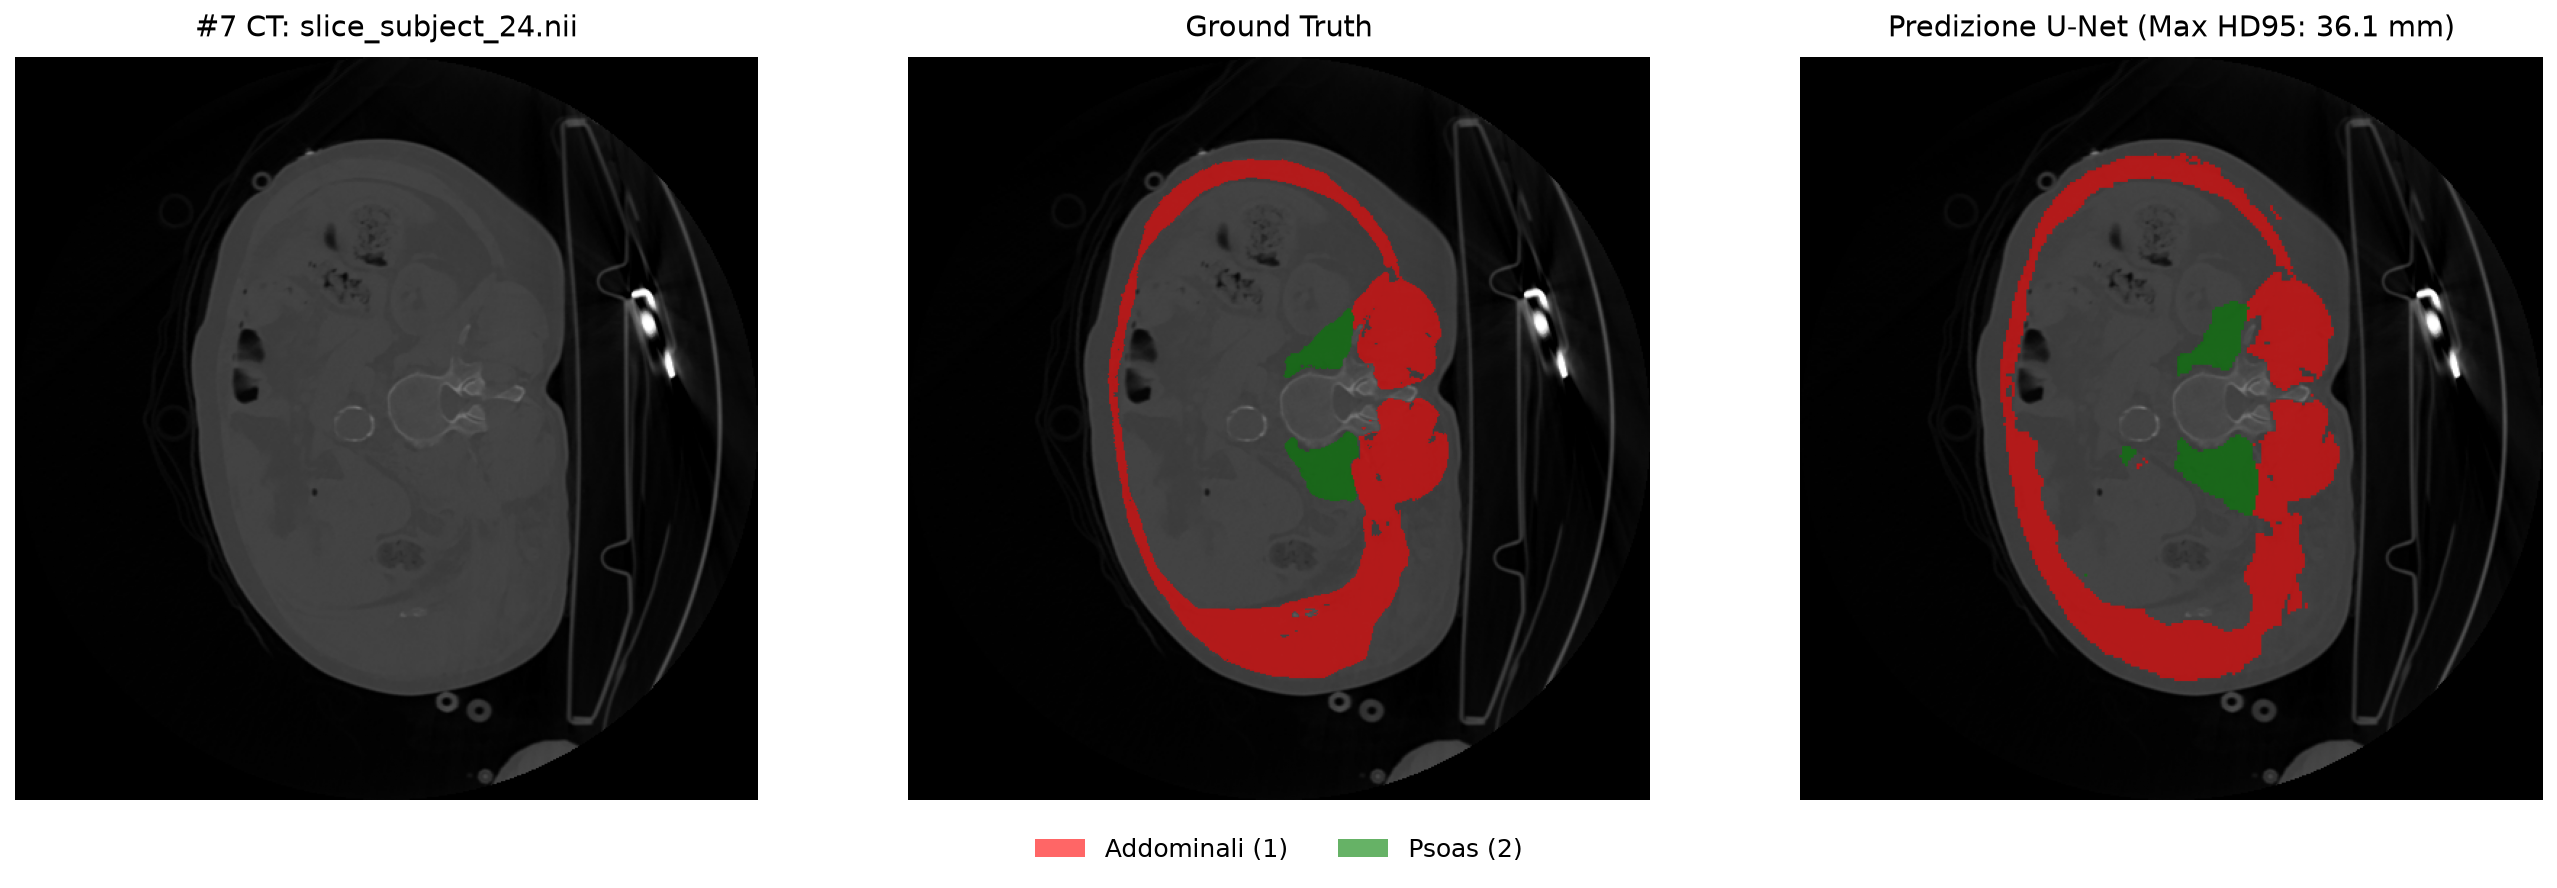

In [12]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
import numpy as np
import nibabel as nib
import tensorflow as tf

print("Ricerca dei casi clinici con il peggior errore spaziale (Max HD95) e calcolo metriche complete...")

classifica_errori = []
TARGET_SIZE = (256, 256)
HU_MIN, HU_MAX = -30.0, 150.0

# 1. SCANSIONE DI TUTTO IL DATASET
for i, (ct_path, mask_path) in enumerate(zip(external_ct_files, external_mask_files)):
    nii_ct = nib.load(ct_path)
    nii_mask = nib.load(mask_path)
    
    original_data = np.squeeze(nii_ct.get_fdata())
    true_mask = np.squeeze(nii_mask.get_fdata())
    original_zooms = nii_ct.header.get_zooms()
    original_shape = original_data.shape
    
    # Preprocessing & Inferenza
    img_np = np.clip(original_data, HU_MIN, HU_MAX)
    img_np = (img_np - HU_MIN) / (HU_MAX - HU_MIN)
    
    img_tensor = tf.expand_dims(tf.convert_to_tensor(img_np, dtype=tf.float32), axis=-1)
    img_resized = tf.image.resize(img_tensor, TARGET_SIZE, method='bilinear').numpy()
    input_batch = np.expand_dims(img_resized, axis=0)
    
    preds = model.predict(input_batch, verbose=0)
    pred_mask_256 = np.argmax(preds, axis=-1)[0]
    
    pred_mask = tf.image.resize(
        np.expand_dims(pred_mask_256, axis=-1),
        original_shape[:2], 
        method='nearest'
    ).numpy().squeeze()
    
    # Spaziatura in mm (Salviamo sp_y e sp_x per calcolare bAHD dopo)
    spacing_x_mm = original_zooms[0]
    spacing_y_mm = original_zooms[1]
    
    hd95_abs = calculate_HD95_single_class_mm(true_mask == 1, pred_mask == 1, spacing_y_mm, spacing_x_mm)
    hd95_psoas = calculate_HD95_single_class_mm(true_mask == 2, pred_mask == 2, spacing_y_mm, spacing_x_mm)
    
    val_abs = hd95_abs if not np.isnan(hd95_abs) else 0.0
    val_psoas = hd95_psoas if not np.isnan(hd95_psoas) else 0.0
    max_hd95_paziente = max(val_abs, val_psoas)
    
    # Salviamo tutti i dati necessari inclusa la spaziatura!
    classifica_errori.append((i, max_hd95_paziente, ct_path.name, original_data, true_mask, pred_mask, spacing_y_mm, spacing_x_mm))

# 2. ORDINAMENTO DECRESCENTE 
classifica_errori.sort(key=lambda x: x[1], reverse=True)
top_peggiori = classifica_errori[:7] # Modifica questo numero per mostrare più o meno pazienti

print("\n==================================================")
print(f" I {len(top_peggiori)} CASI PEGGIORI (WORST-CASE SCENARIOS)")
print("==================================================")

def calc_metrics_ext(y_true, y_pred, class_val, spacing_y, spacing_x):
    t_mask = (y_true == class_val)
    p_mask = (y_pred == class_val)
    inter = np.sum(t_mask & p_mask)
    sum_m = np.sum(t_mask) + np.sum(p_mask)
    dice = (2.0 * inter) / sum_m if sum_m > 0 else 0
    iou = inter / (sum_m - inter) if (sum_m - inter) > 0 else 0
    bahd = calculate_bAHD_single_class_mm(t_mask, p_mask, spacing_y, spacing_x)
    hd95 = calculate_HD95_single_class_mm(t_mask, p_mask, spacing_y, spacing_x)
    return dice, iou, bahd, hd95

cmap_masks = mcolors.ListedColormap(['none', 'red', 'green'])
legend_elements = [
    Patch(facecolor='red', alpha=0.6, label='Addominali (1)'),
    Patch(facecolor='green', alpha=0.6, label='Psoas (2)')
]

# 3. VISUALIZZAZIONE E STAMPA METRICHE
for rank, (idx, errore_mm, nome_file, img_ct, mask_vera, mask_pred, sp_y, sp_x) in enumerate(top_peggiori):
    
    # Calcoliamo le metriche complete per questo specifico peggior caso
    dice_abs, iou_abs, bahd_abs, hd95_abs = calc_metrics_ext(mask_vera, mask_pred, 1, sp_y, sp_x)
    dice_psoas, iou_psoas, bahd_psoas, hd95_psoas = calc_metrics_ext(mask_vera, mask_pred, 2, sp_y, sp_x)
    
    print(f"\n#{rank+1} - {nome_file} | Errore Massimo HD95: {errore_mm:.2f} mm")
    print(f"   ADDOMINALI -> Dice: {dice_abs:.4f} | IoU: {iou_abs:.4f} | bAHD: {bahd_abs:.2f} mm | HD95: {hd95_abs:.2f} mm")
    print(f"   PSOAS      -> Dice: {dice_psoas:.4f} | IoU: {iou_psoas:.4f} | bAHD: {bahd_psoas:.2f} mm | HD95: {hd95_psoas:.2f} mm")
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=150)
    fig.patch.set_facecolor('white')
    
    axes[0].imshow(img_ct, cmap='gray')
    axes[0].set_title(f'#{rank+1} CT: {nome_file}', fontsize=14, pad=10)
    axes[0].axis('off')

    axes[1].imshow(img_ct, cmap='gray')
    mask_true_masked = np.ma.masked_where(mask_vera == 0, mask_vera)
    axes[1].imshow(mask_true_masked, cmap=cmap_masks, alpha=0.6, vmin=0, vmax=2)
    axes[1].set_title('Ground Truth', fontsize=14, pad=10)
    axes[1].axis('off')

    axes[2].imshow(img_ct, cmap='gray')
    mask_pred_masked = np.ma.masked_where(mask_pred == 0, mask_pred)
    axes[2].imshow(mask_pred_masked, cmap=cmap_masks, alpha=0.6, vmin=0, vmax=2)
    axes[2].set_title(f'Predizione U-Net (Max HD95: {errore_mm:.1f} mm)', fontsize=14, pad=10)
    axes[2].axis('off')

    fig.legend(handles=legend_elements, loc='lower center', ncol=2, bbox_to_anchor=(0.5, 0.05), fontsize=12, frameon=False)
    plt.tight_layout(rect=[0, 0.12, 1, 1])
    
    # plt.savefig(f"tesi_WorstCase_{rank+1}_{nome_file.replace('.nii','')}.png", bbox_inches='tight', facecolor='white')
    plt.show()

best worst based on HD95

Ricerca del miglior e peggior caso nella Independent Cohort (basato su Dice Globale)...

 MIGLIOR CASO INDEPENDENT COHORT (slice_subject_28.nii)
ADDOMINALI -> Dice: 0.9347 | IoU: 0.8774 | bAHD: 2.56 mm | HD95: 27.48 mm
PSOAS      -> Dice: 0.8784 | IoU: 0.7831 | bAHD: 2.03 mm | HD95: 6.11 mm


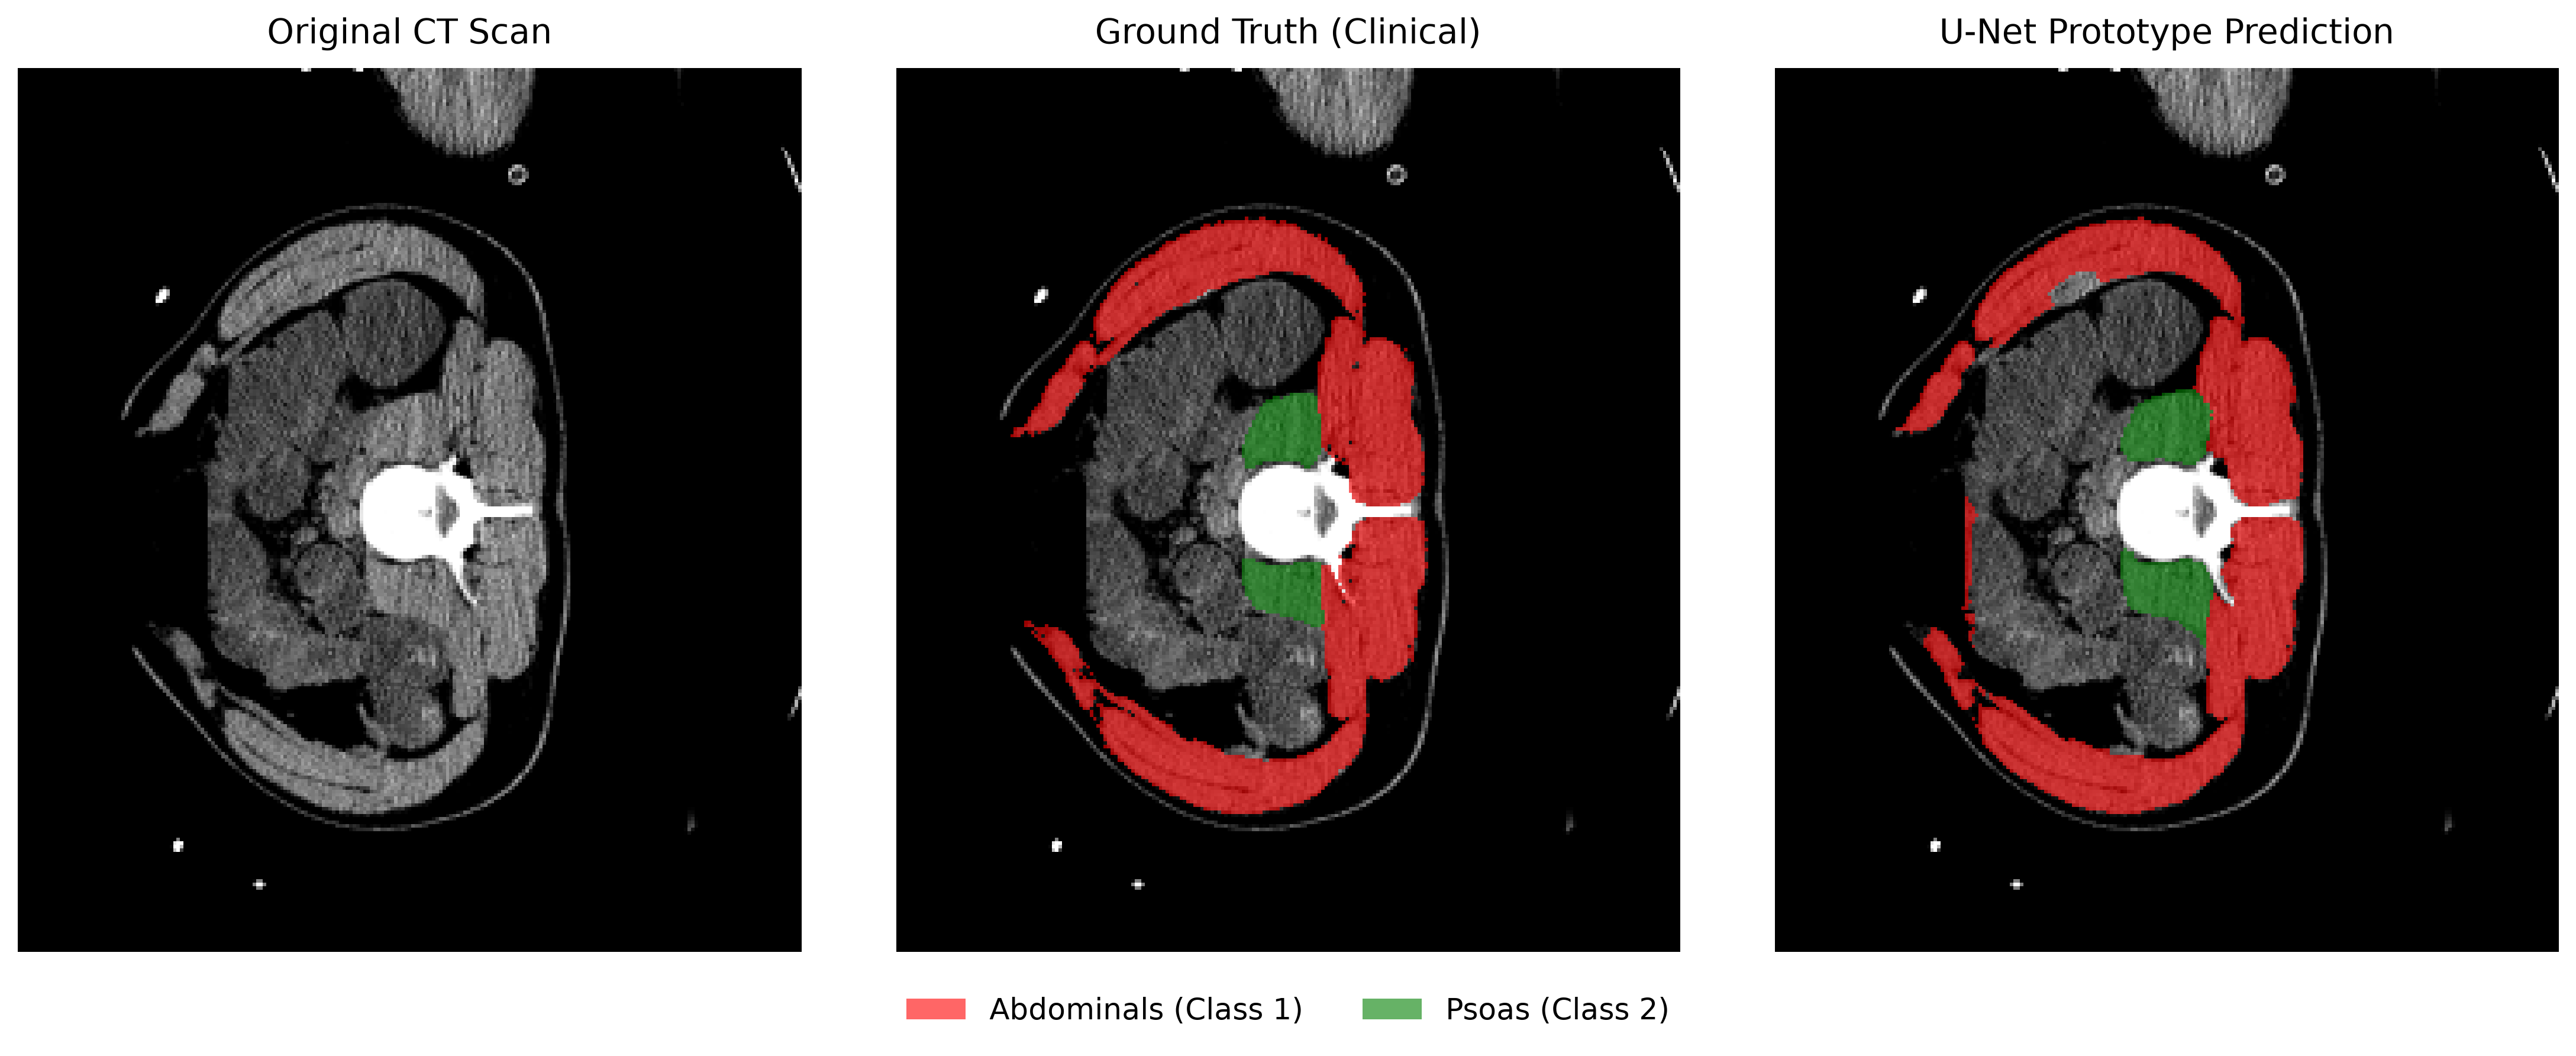


 PEGGIOR CASO INDEPENDENT COHORT (slice_subject_5.nii)
ADDOMINALI -> Dice: 0.6393 | IoU: 0.4698 | bAHD: 8.36 mm | HD95: 49.27 mm
PSOAS      -> Dice: 0.7941 | IoU: 0.6586 | bAHD: 3.96 mm | HD95: 14.91 mm


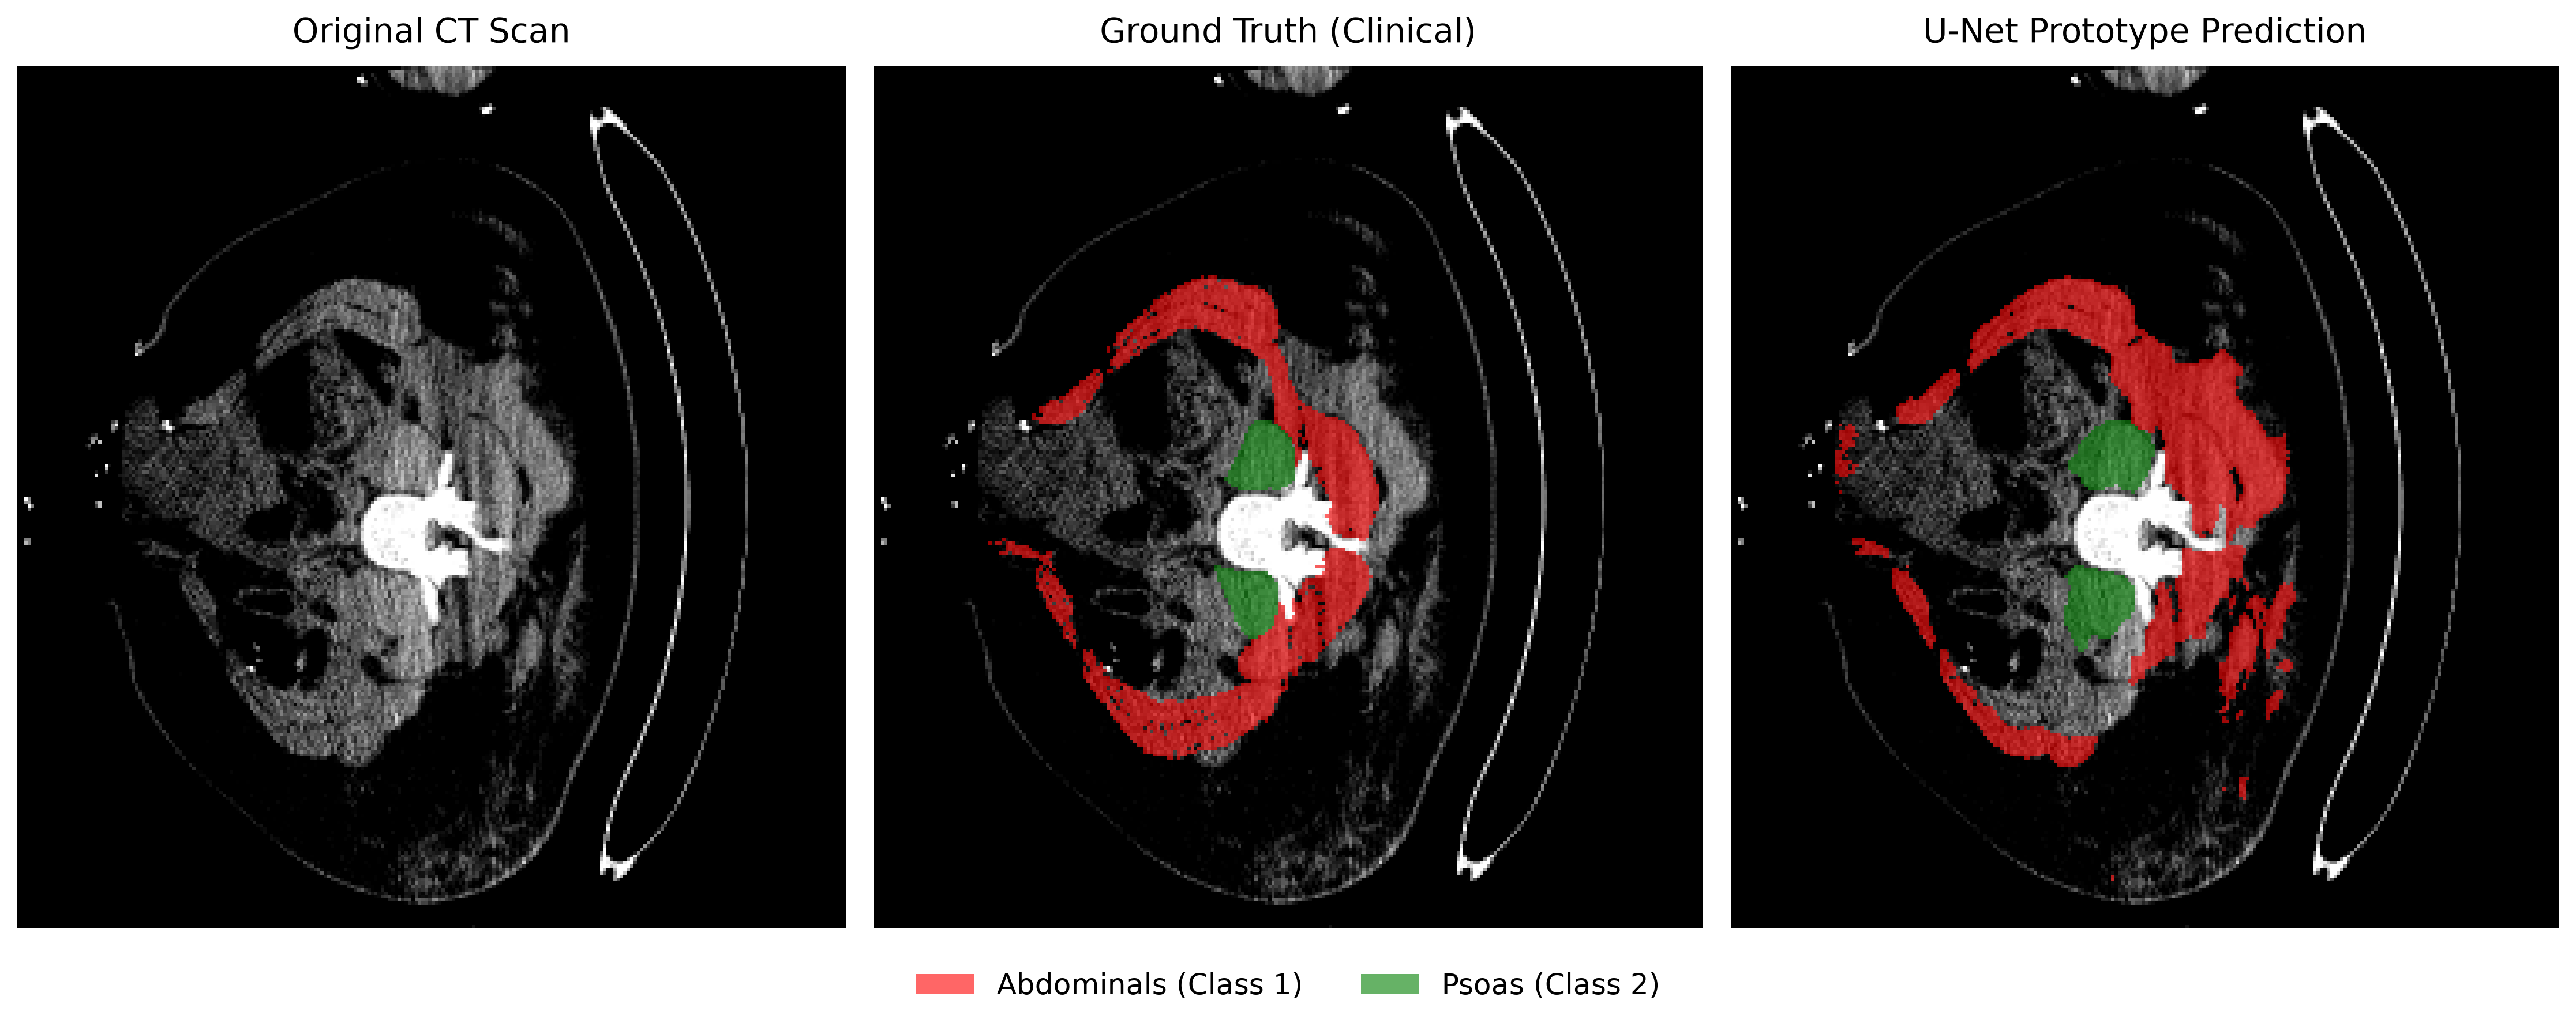

In [13]:
import numpy as np
import nibabel as nib
import tensorflow as tf

print("Ricerca del miglior e peggior caso nella Independent Cohort (basato su Dice Globale)...")

casi_external = []
TARGET_SIZE = (256, 256)
HU_MIN, HU_MAX = -30.0, 150.0

# 1. Ricerca Veloce di Tutti i Casi
for ct_path, mask_path in zip(external_ct_files, external_mask_files):
    nii_ct = nib.load(ct_path)
    nii_mask = nib.load(mask_path)
    original_data = np.squeeze(nii_ct.get_fdata())
    true_mask = np.squeeze(nii_mask.get_fdata())
    
    img_np = np.clip(original_data, HU_MIN, HU_MAX)
    img_np = (img_np - HU_MIN) / (HU_MAX - HU_MIN)
    img_tensor = tf.expand_dims(tf.convert_to_tensor(img_np, dtype=tf.float32), axis=-1)
    img_resized = tf.image.resize(img_tensor, TARGET_SIZE, method='bilinear').numpy()
    
    preds = model.predict(np.expand_dims(img_resized, axis=0), verbose=0)
    pred_mask_256 = np.argmax(preds, axis=-1)[0]
    
    pred_mask = tf.image.resize(np.expand_dims(pred_mask_256, axis=-1), original_data.shape[:2], method='nearest').numpy().squeeze()
    
    # Calcolo Dice globale (tutte le classi foreground assieme) per fare la classifica
    intersection = np.sum((true_mask > 0) & (pred_mask > 0))
    sum_masks = np.sum(true_mask > 0) + np.sum(pred_mask > 0)
    
    if sum_masks > 0:
        dice_score = (2.0 * intersection) / sum_masks
        casi_external.append((dice_score, ct_path, mask_path, img_resized, pred_mask_256))

# Ordino la lista dal Dice più alto al più basso
casi_external.sort(key=lambda x: x[0], reverse=True)

# 2. Definizione della funzione per le metriche
def calc_ext_metrics(y_true, y_pred, class_val, spacing_y, spacing_x):
    t_mask = (y_true == class_val)
    p_mask = (y_pred == class_val)
    inter = np.sum(t_mask & p_mask)
    sum_m = np.sum(t_mask) + np.sum(p_mask)
    dice = (2.0 * inter) / sum_m if sum_m > 0 else 0
    iou = inter / (sum_m - inter) if (sum_m - inter) > 0 else 0
    bahd = calculate_bAHD_single_class_mm(t_mask, p_mask, spacing_y, spacing_x)
    hd95 = calculate_HD95_single_class_mm(t_mask, p_mask, spacing_y, spacing_x)
    return dice, iou, bahd, hd95

# 3. Estrazione dei casi Estremi: Indice 0 (Migliore) e Indice -1 (Peggiore)
casi_estremi = [
    ("MIGLIOR CASO", casi_external[0]),
    ("PEGGIOR CASO", casi_external[-1])
]

for label, caso in casi_estremi:
    dice_totale, ct_path, mask_path, img_resized, pred_mask_256 = caso
    
    # Ricarico il file originale per estrarre la spaziatura reale (mm)
    nii_ct = nib.load(ct_path)
    nii_mask = nib.load(mask_path)
    true_mask = np.squeeze(nii_mask.get_fdata())
    original_shape = true_mask.shape
    original_zooms = nii_ct.header.get_zooms()
    
    # Riporto la predizione alla geometria nativa
    pred_mask = tf.image.resize(np.expand_dims(pred_mask_256, axis=-1), original_shape[:2], method='nearest').numpy().squeeze()
    
    spacing_x_mm = original_zooms[0]
    spacing_y_mm = original_zooms[1]
    
    # Calcolo metriche per classe
    ext_dice_abs, ext_iou_abs, ext_bahd_abs, ext_hd95_abs = calc_ext_metrics(true_mask, pred_mask, 1, spacing_y_mm, spacing_x_mm)
    ext_dice_psoas, ext_iou_psoas, ext_bahd_psoas, ext_hd95_psoas = calc_ext_metrics(true_mask, pred_mask, 2, spacing_y_mm, spacing_x_mm)

    print("\n==================================================")
    print(f" {label} INDEPENDENT COHORT ({ct_path.name})")
    print("==================================================")
    print(f"ADDOMINALI -> Dice: {ext_dice_abs:.4f} | IoU: {ext_iou_abs:.4f} | bAHD: {ext_bahd_abs:.2f} mm | HD95: {ext_hd95_abs:.2f} mm")
    print(f"PSOAS      -> Dice: {ext_dice_psoas:.4f} | IoU: {ext_iou_psoas:.4f} | bAHD: {ext_bahd_psoas:.2f} mm | HD95: {ext_hd95_psoas:.2f} mm")
    print("==================================================")
    
    plot_step2_segmentation(
        ct_slice=img_resized, 
        true_mask=tf.image.resize(np.expand_dims(true_mask, axis=-1), TARGET_SIZE, method='nearest').numpy().squeeze(), 
        pred_mask=pred_mask_256, 
        slice_idx=f"{label.replace(' ', '')}_{ct_path.name.replace('.nii','')}" 
    )

Dice worst best case scenario

Ricerca del MIGLIORE e PEGGIOR caso basati sul DICE SCORE nella Independent Cohort...

 IL MIGLIORE CASO INDEPENDENT (File: slice_subject_30.nii)
ADDOMINALI -> Dice: 0.9337 | IoU: 0.8756 | bAHD: 1.12 mm | HD95: 5.92 mm
PSOAS      -> Dice: 0.9485 | IoU: 0.9020 | bAHD: 0.95 mm | HD95: 2.52 mm
(DICE MEDIO SLICE: 0.9411)


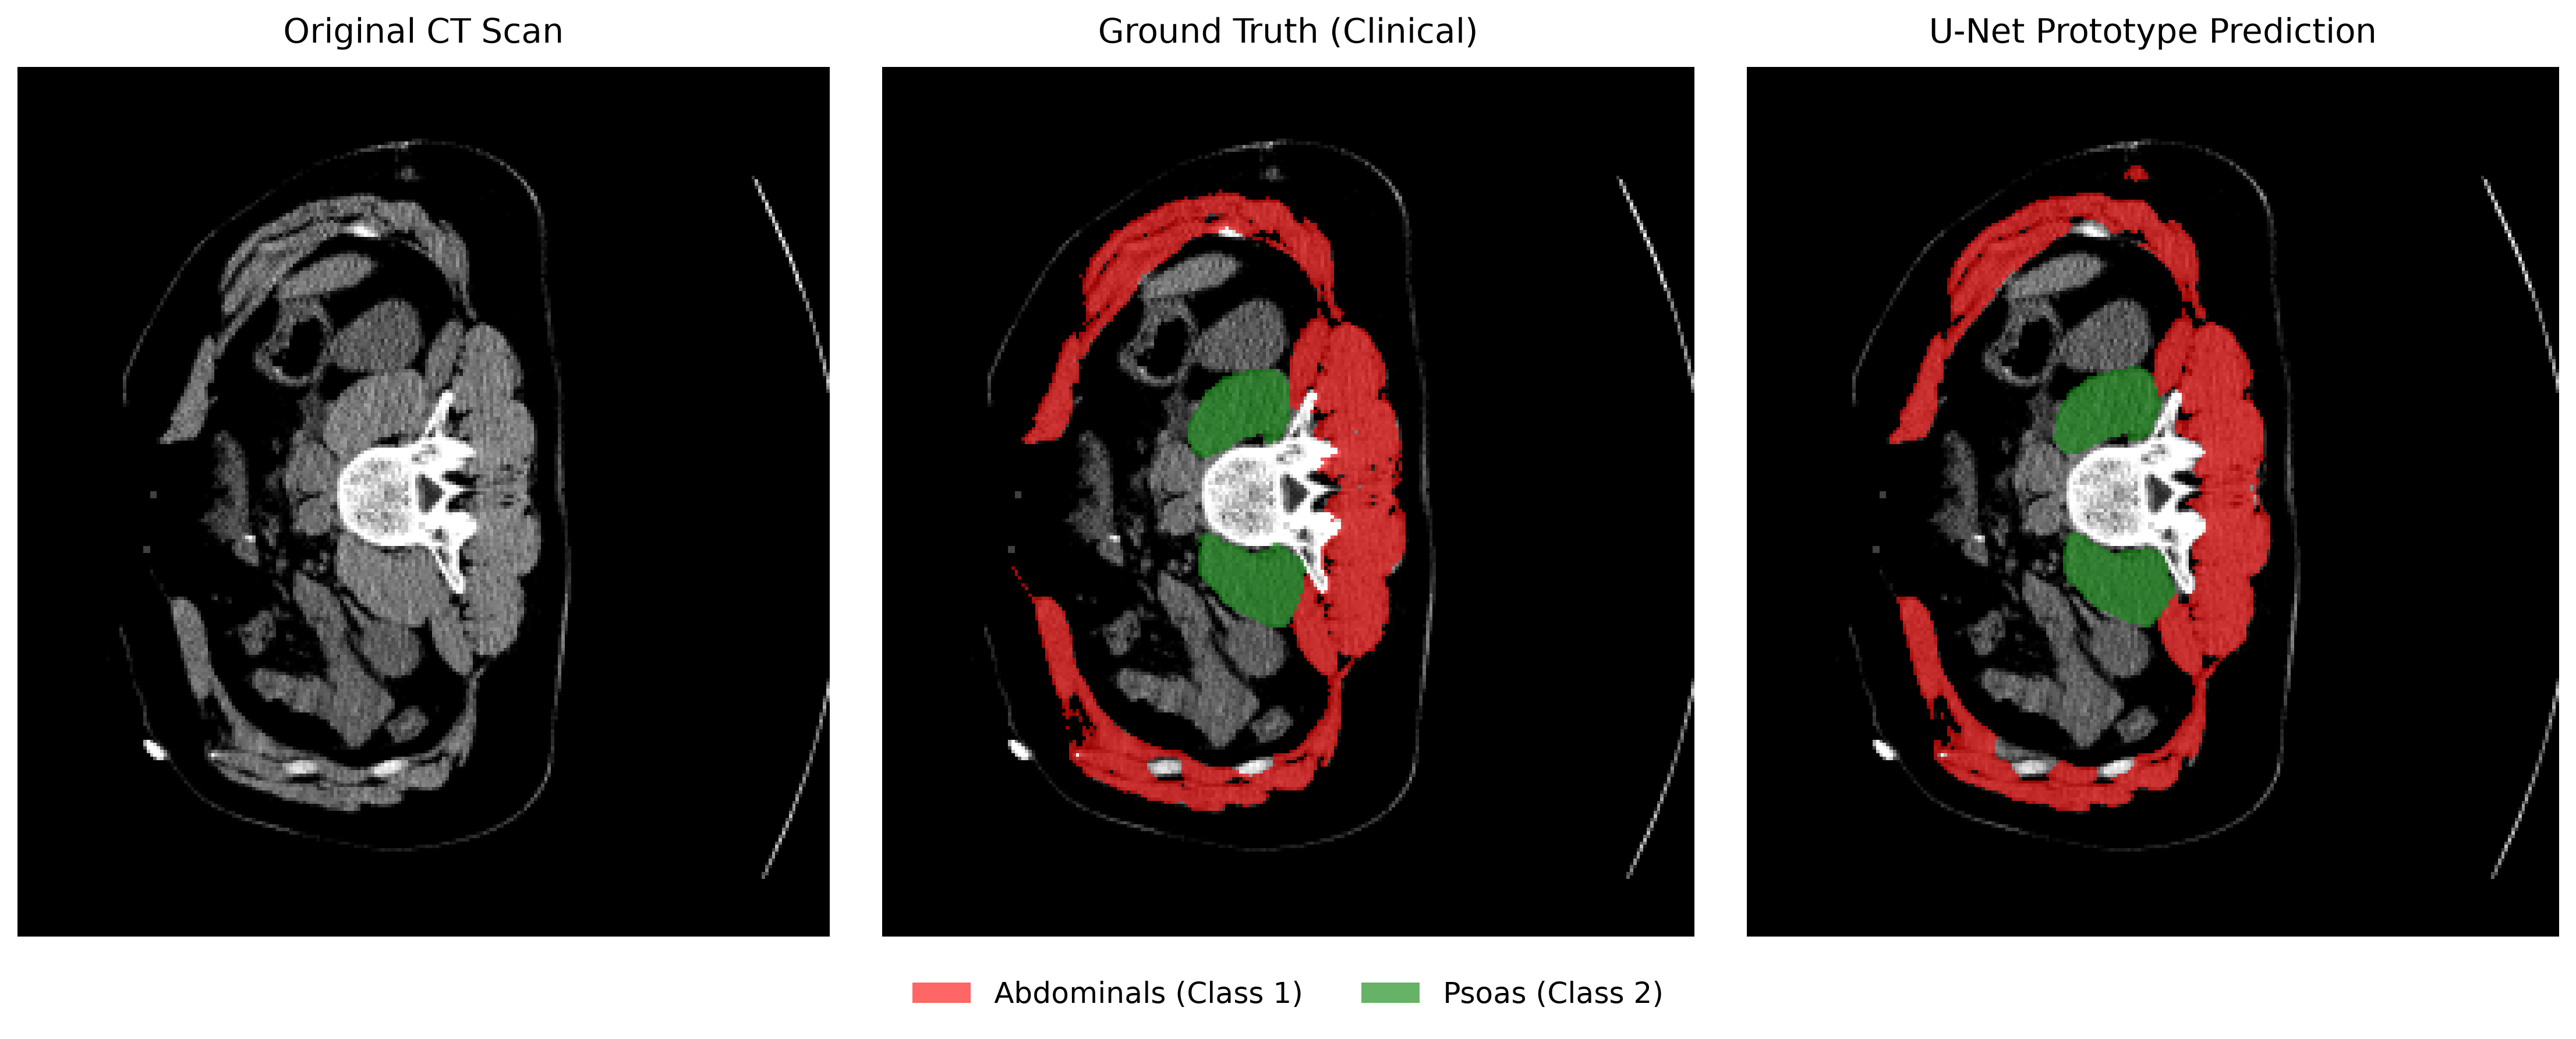


 IL PEGGIORE CASO INDEPENDENT (File: slice_subject_5.nii)
ADDOMINALI -> Dice: 0.6393 | IoU: 0.4698 | bAHD: 8.36 mm | HD95: 49.27 mm
PSOAS      -> Dice: 0.7941 | IoU: 0.6586 | bAHD: 3.96 mm | HD95: 14.91 mm
(DICE MEDIO SLICE: 0.7167)


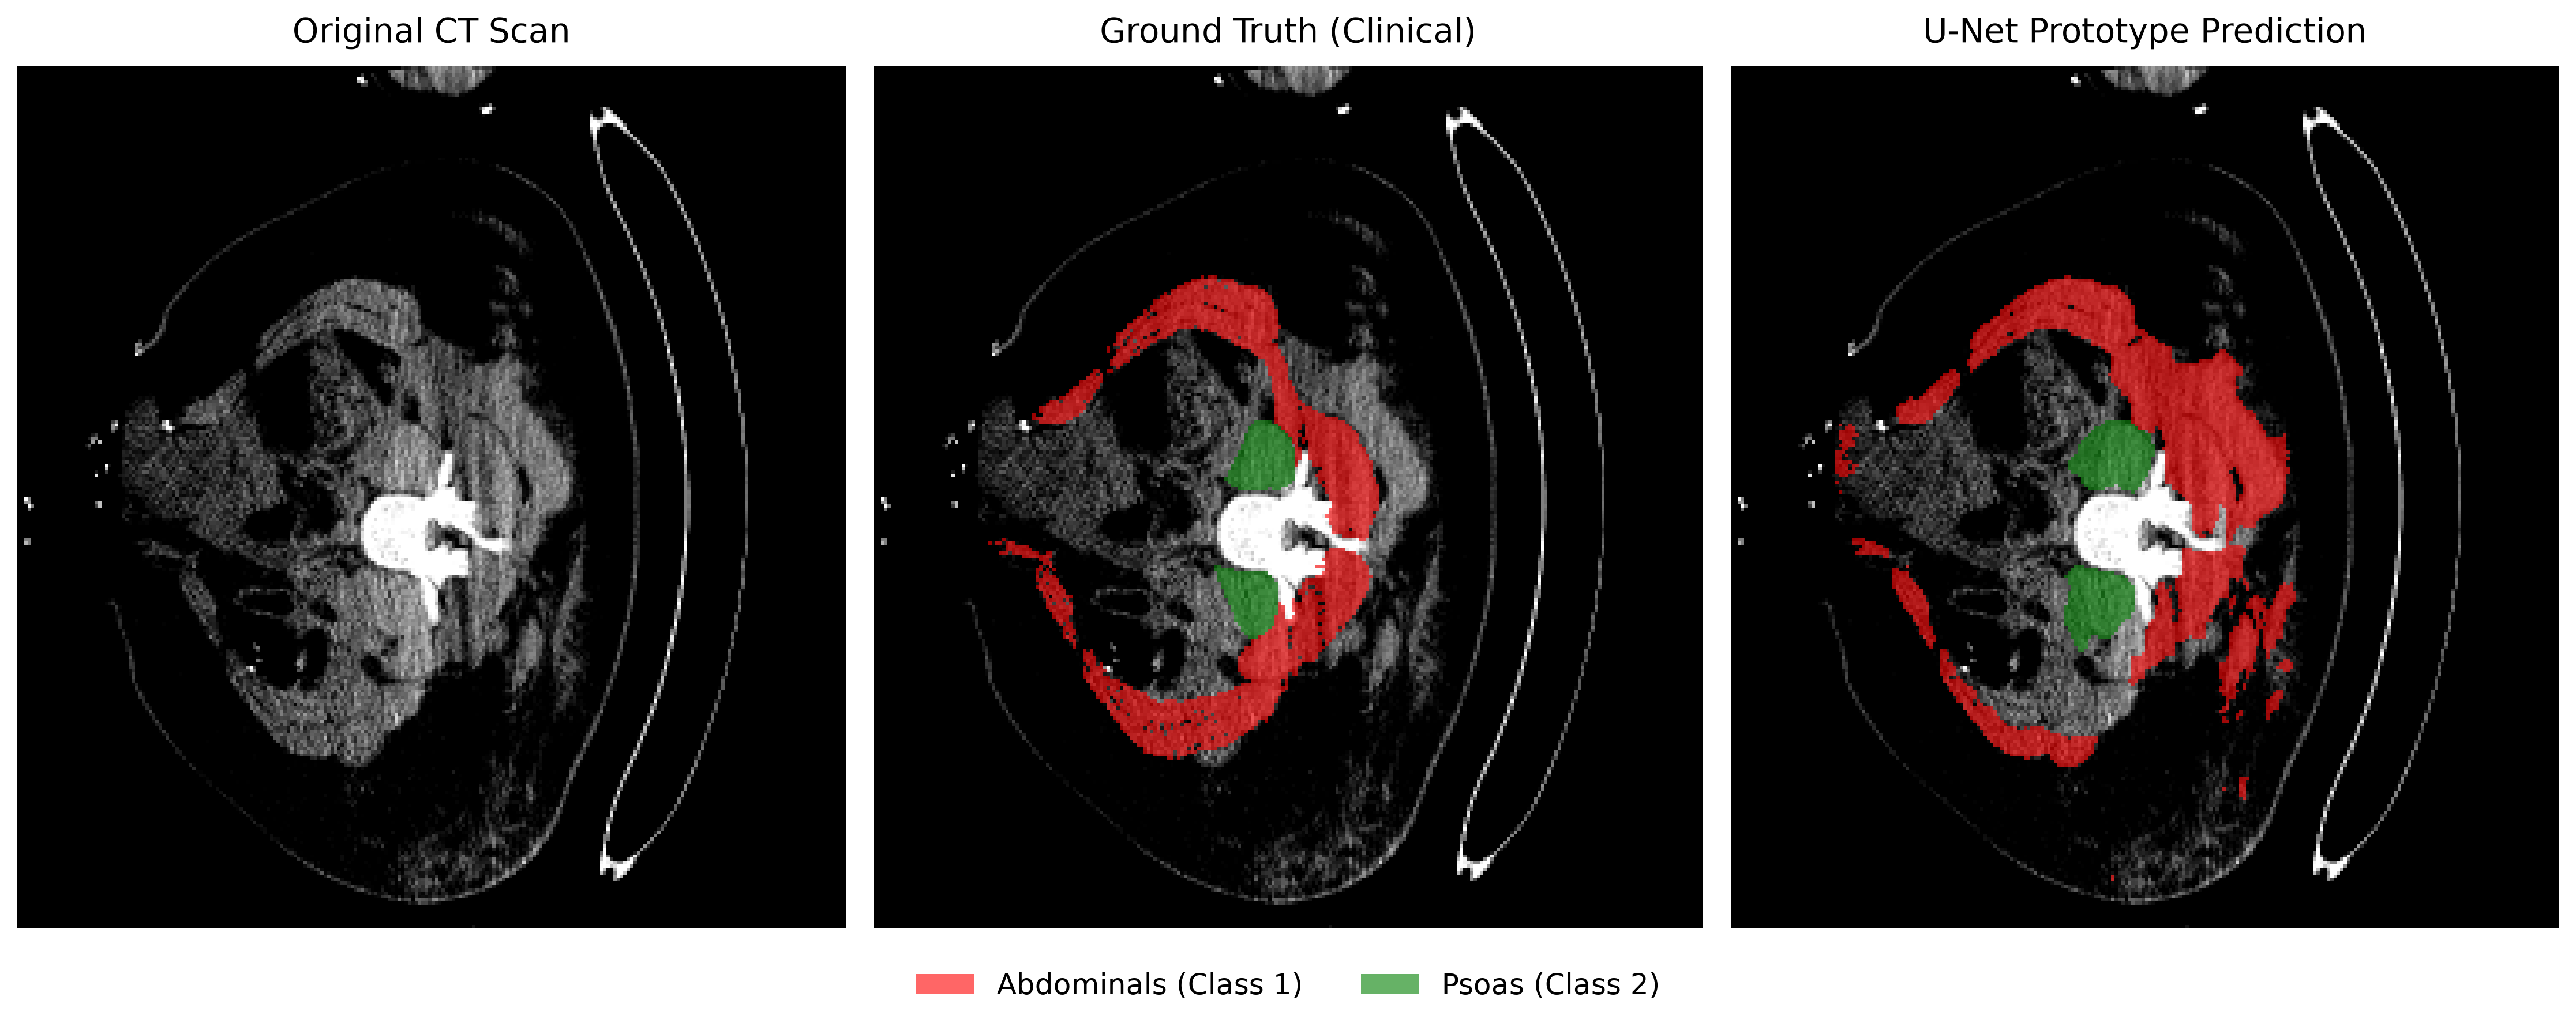

In [14]:
import numpy as np
import nibabel as nib
import tensorflow as tf

print("Ricerca del MIGLIORE e PEGGIOR caso basati sul DICE SCORE nella Independent Cohort...")

classifica_external = []
TARGET_SIZE = (256, 256)
HU_MIN, HU_MAX = -30.0, 150.0

def calc_all_metrics_ext(y_true, y_pred, class_val, spacing_y, spacing_x):
    t_mask = (y_true == class_val)
    p_mask = (y_pred == class_val)
    inter = np.sum(t_mask & p_mask)
    sum_m = np.sum(t_mask) + np.sum(p_mask)
    dice = (2.0 * inter) / sum_m if sum_m > 0 else 0
    iou = inter / (sum_m - inter) if (sum_m - inter) > 0 else 0
    bahd = calculate_bAHD_single_class_mm(t_mask, p_mask, spacing_y, spacing_x)
    hd95 = calculate_HD95_single_class_mm(t_mask, p_mask, spacing_y, spacing_x)
    return dice, iou, bahd, hd95

# 1. Scansione di tutto il Dataset Esterno
for i, (ct_path, mask_path) in enumerate(zip(external_ct_files, external_mask_files)):
    nii_ct = nib.load(ct_path)
    nii_mask = nib.load(mask_path)
    
    original_data = np.squeeze(nii_ct.get_fdata())
    true_mask = np.squeeze(nii_mask.get_fdata())
    original_zooms = nii_ct.header.get_zooms()
    original_shape = original_data.shape
    
    # Preprocessing
    img_np = np.clip(original_data, HU_MIN, HU_MAX)
    img_np = (img_np - HU_MIN) / (HU_MAX - HU_MIN)
    img_tensor = tf.expand_dims(tf.convert_to_tensor(img_np, dtype=tf.float32), axis=-1)
    img_resized = tf.image.resize(img_tensor, TARGET_SIZE, method='bilinear').numpy()
    
    # Inferenza
    preds = model.predict(np.expand_dims(img_resized, axis=0), verbose=0)
    pred_mask_256 = np.argmax(preds, axis=-1)[0]
    
    pred_mask = tf.image.resize(
        np.expand_dims(pred_mask_256, axis=-1),
        original_shape[:2], 
        method='nearest'
    ).numpy().squeeze()
    
    spacing_x_mm = original_zooms[0]
    spacing_y_mm = original_zooms[1]
    
    # --- MODIFICA: Calcolo veloce del Dice Score per l'ordinamento ---
    
    # Addominali (Classe 1)
    t_abs = (true_mask == 1)
    p_abs = (pred_mask == 1)
    sum_abs = np.sum(t_abs) + np.sum(p_abs)
    dice_abs = (2.0 * np.sum(t_abs & p_abs)) / sum_abs if sum_abs > 0 else 0
    
    # Psoas (Classe 2)
    t_psoas = (true_mask == 2)
    p_psoas = (pred_mask == 2)
    sum_psoas = np.sum(t_psoas) + np.sum(p_psoas)
    dice_psoas = (2.0 * np.sum(t_psoas & p_psoas)) / sum_psoas if sum_psoas > 0 else 0
    
    # Criterio di ordinamento: usiamo il Dice Score Medio tra le due classi
    avg_dice = (dice_abs + dice_psoas) / 2.0
    
    # Ignora i casi anomali vuoti
    if sum_abs == 0 and sum_psoas == 0:
        continue
        
    classifica_external.append((avg_dice, ct_path, mask_path, img_resized, pred_mask_256, spacing_y_mm, spacing_x_mm, true_mask, pred_mask))

# 2. Ordinamento DECRESCENTE (Massimo Dice -> Minimo Dice)
# Impostando reverse=True, il Dice più alto (1.0) va in cima [0], il più basso in fondo [-1]
classifica_external.sort(key=lambda x: x[0], reverse=True)

casi_da_stampare = {
    "IL MIGLIORE": classifica_external[0],   # Massimo overlap volumetrico
    "IL PEGGIORE": classifica_external[-1]   # Minimo overlap volumetrico
}

# 3. Estrazione e Plot
for titolo, dati in casi_da_stampare.items():
    avg_dice, ct_path, mask_path, img_resized, pred_mask_256, sp_y, sp_x, true_mask, pred_mask = dati

    # Qui calcola tutte le metriche (compreso HD95) solo per i due casi estremi
    dice_abs, iou_abs, bahd_abs, hd95_abs = calc_all_metrics_ext(true_mask, pred_mask, 1, sp_y, sp_x)
    dice_psoas, iou_psoas, bahd_psoas, hd95_psoas = calc_all_metrics_ext(true_mask, pred_mask, 2, sp_y, sp_x)

    print("\n==================================================")
    print(f" {titolo} CASO INDEPENDENT (File: {ct_path.name})")
    print("==================================================")
    print(f"ADDOMINALI -> Dice: {dice_abs:.4f} | IoU: {iou_abs:.4f} | bAHD: {bahd_abs:.2f} mm | HD95: {hd95_abs:.2f} mm")
    print(f"PSOAS      -> Dice: {dice_psoas:.4f} | IoU: {iou_psoas:.4f} | bAHD: {bahd_psoas:.2f} mm | HD95: {hd95_psoas:.2f} mm")
    print(f"(DICE MEDIO SLICE: {avg_dice:.4f})")
    
    label_tipo = "Best" if "MIGLIORE" in titolo else "Worst"
    
    plot_step2_segmentation(
        ct_slice=img_resized, 
        true_mask=tf.image.resize(np.expand_dims(true_mask, axis=-1), TARGET_SIZE, method='nearest').numpy().squeeze(), 
        pred_mask=pred_mask_256, 
        slice_idx=f"{label_tipo}External_{ct_path.name.replace('.nii','')}_AvgDice_{avg_dice:.4f}" 
    )

calculate failure examples 


In [ ]:
import numpy as np
import nibabel as nib
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from scipy.ndimage import label
import os

print("Avvio Auditing Qualitativo Sistematico sui 86 pazienti...")

TARGET_SIZE = (256, 256)
HU_MIN, HU_MAX = -30.0, 150.0

# 1. Creazione delle cartelle ordinate per classe
output_dir_abs = os.path.join("Failure_Modes_Analysis", "Abdominals")
output_dir_psoas = os.path.join("Failure_Modes_Analysis", "Psoas")
os.makedirs(output_dir_abs, exist_ok=True)
os.makedirs(output_dir_psoas, exist_ok=True)

# Soglia di attenzione in millimetri (Oltre i 30mm è un errore clinicamente rilevante)
HD95_THRESHOLD = 20.0 
anomalie_rilevate = []

# 2. Scansione e Calcolo
for ct_path, mask_path in zip(external_ct_files, external_mask_files):
    nii_ct = nib.load(ct_path)
    nii_mask = nib.load(mask_path)
    
    original_data = np.squeeze(nii_ct.get_fdata())
    true_mask = np.squeeze(nii_mask.get_fdata())
    original_shape = original_data.shape
    original_zooms = nii_ct.header.get_zooms()
    
    # Preprocessing e Inferenza
    img_np = np.clip(original_data, HU_MIN, HU_MAX)
    img_np = (img_np - HU_MIN) / (HU_MAX - HU_MIN)
    img_tensor = tf.expand_dims(tf.convert_to_tensor(img_np, dtype=tf.float32), axis=-1)
    img_resized = tf.image.resize(img_tensor, TARGET_SIZE, method='bilinear').numpy()
    
    preds = model.predict(np.expand_dims(img_resized, axis=0), verbose=0)
    pred_mask_256 = np.argmax(preds, axis=-1)[0]
    
    pred_mask = tf.image.resize(
        np.expand_dims(pred_mask_256, axis=-1),
        original_shape[:2], method='nearest'
    ).numpy().squeeze()
    
    spacing_x_mm = original_zooms[0]
    spacing_y_mm = original_zooms[1]
    
    # Analisi per singola classe
    for class_id, class_name in zip([1, 2], ["Addominali", "Psoas"]):
        t_mask = (true_mask == class_id)
        p_mask = (pred_mask == class_id)
        
        inter = np.sum(t_mask & p_mask)
        sum_m = np.sum(t_mask) + np.sum(p_mask)
        dice = (2.0 * inter) / sum_m if sum_m > 0 else 0
        hd95 = calculate_HD95_single_class_mm(t_mask, p_mask, spacing_y_mm, spacing_x_mm)
        
        # Salvataggio anomalie
        if not np.isnan(hd95) and hd95 > HD95_THRESHOLD:
            labeled_pred, num_features = label(p_mask)
            anomalie_rilevate.append({
                'file': ct_path.name,
                'classe': class_name,
                'dice': dice,
                'hd95': hd95,
                'isole': num_features,
                'img': original_data,
                't_mask': true_mask,
                'p_mask': pred_mask
            })

print(f"\nTrovate {len(anomalie_rilevate)} istanze con errore spaziale severo (> {HD95_THRESHOLD} mm).")

# 3. Generazione Plot e Salvataggio Ordinato
cmap_masks = mcolors.ListedColormap(['none', 'red', 'green'])
legend_elements = [
    Patch(facecolor='red', alpha=0.6, label='Addominali (1)'), 
    Patch(facecolor='green', alpha=0.6, label='Psoas (2)')
]

for idx, anomalia in enumerate(anomalie_rilevate):
    file_name = anomalia['file']
    
    # Smistamento cartella di destinazione
    if anomalia['classe'] == "Addominali":
        cartella_destinazione = output_dir_abs
    else:
        cartella_destinazione = output_dir_psoas
        
    # Classificazione testuale solo per log a terminale
    if anomalia['dice'] > 0.80:
        categoria = "PARADOSSO (Alto Dice, Alto HD95)"
    else:
        categoria = "FALLIMENTO GLOBALE (Basso Dice, Alto HD95)"
        
    print(f"- {file_name} ({anomalia['classe']}): HD95 {anomalia['hd95']:.1f}mm | Dice {anomalia['dice']:.2f} | {categoria}")
    
    # Disegno Immagini
    fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=150)
    fig.patch.set_facecolor('white')
    
    axes[0].imshow(anomalia['img'], cmap='gray')
    axes[0].set_title(f"CT: {file_name}", fontsize=14, pad=10)
    axes[0].axis('off')

    axes[1].imshow(anomalia['img'], cmap='gray')
    axes[1].imshow(np.ma.masked_where(anomalia['t_mask'] == 0, anomalia['t_mask']), cmap=cmap_masks, alpha=0.6, vmin=0, vmax=2)
    axes[1].set_title("Ground Truth", fontsize=14, pad=10)
    axes[1].axis('off')

    axes[2].imshow(anomalia['img'], cmap='gray')
    axes[2].imshow(np.ma.masked_where(anomalia['p_mask'] == 0, anomalia['p_mask']), cmap=cmap_masks, alpha=0.6, vmin=0, vmax=2)
    axes[2].set_title(f"Predizione | HD95: {anomalia['hd95']:.1f}mm | Dice: {anomalia['dice']:.2f}", fontsize=14, pad=10)
    axes[2].axis('off')

    # Nessun titolo sovrapposto
    plt.tight_layout()
    
    # Salvataggio nella cartella corretta
    percorso_salvataggio = os.path.join(cartella_destinazione, f"Anomalia_{file_name.replace('.nii','')}.png")
    # plt.savefig(percorso_salvataggio, bbox_inches='tight', facecolor='white')
    plt.close() 

print("\nTutte le immagini sono state salvate ordinatamente nelle cartelle 'Abdominals' e 'Psoas'.")

Avvio Auditing Qualitativo Sistematico sui 86 pazienti...

Trovate 25 istanze con errore spaziale severo (> 20.0 mm).
- slice_subject_10.nii (Addominali): HD95 26.2mm | Dice 0.84 | PARADOSSO (Alto Dice, Alto HD95)
- slice_subject_2.nii (Psoas): HD95 25.5mm | Dice 0.49 | FALLIMENTO GLOBALE (Basso Dice, Alto HD95)
- slice_subject_25.nii (Addominali): HD95 83.8mm | Dice 0.88 | PARADOSSO (Alto Dice, Alto HD95)
- slice_subject_25.nii (Psoas): HD95 220.6mm | Dice 0.88 | PARADOSSO (Alto Dice, Alto HD95)
- slice_subject_3.nii (Addominali): HD95 84.1mm | Dice 0.88 | PARADOSSO (Alto Dice, Alto HD95)
- slice_subject_3.nii (Psoas): HD95 35.8mm | Dice 0.48 | FALLIMENTO GLOBALE (Basso Dice, Alto HD95)
- slice_subject_33.nii (Psoas): HD95 26.2mm | Dice 0.57 | FALLIMENTO GLOBALE (Basso Dice, Alto HD95)
- slice_subject_44.nii (Addominali): HD95 65.0mm | Dice 0.62 | FALLIMENTO GLOBALE (Basso Dice, Alto HD95)
- slice_subject_44.nii (Psoas): HD95 179.0mm | Dice 0.79 | FALLIMENTO GLOBALE (Basso Dice, Alto 

Errore sulle misure derivate. Se è tecnicamente fattibile con i dati già disponibili, sarebbe molto utile confrontare direttamente l'area muscolare ottenuta dalla segmentazione predetta con quella derivata dalla ground truth, riportando almeno errore assoluto e relativo e, idealmente, un'analisi di concordanza (ad esempio Bland–Altman). Questo ci permetterebbe di verificare non soltanto la qualità della segmentazione, ma anche l'effetto degli errori sulla misura quantitativa effettivamente derivata dalla pipeline. Per la radiodensità HU possiamo valutare successivamente se i dati consentono un'analisi analoga.


Bland, J.M., & Altman, D.G. (1986). Statistical methods for assessing agreement between two methods of clinical measurement. The Lancet.


 ANALISI ERRORI SULLE MISURE DERIVATE (AREE IN CM²)
L3Muscle (Classi 1+2) -> Errore Assoluto: 10.27 ± 12.48 cm² | Errore Relativo: 6.06% ± 7.63%
L3 Psoas (Classe 2) -> Errore Assoluto: 3.15 ± 2.75 cm² | Errore Relativo: 11.97% ± 9.38%


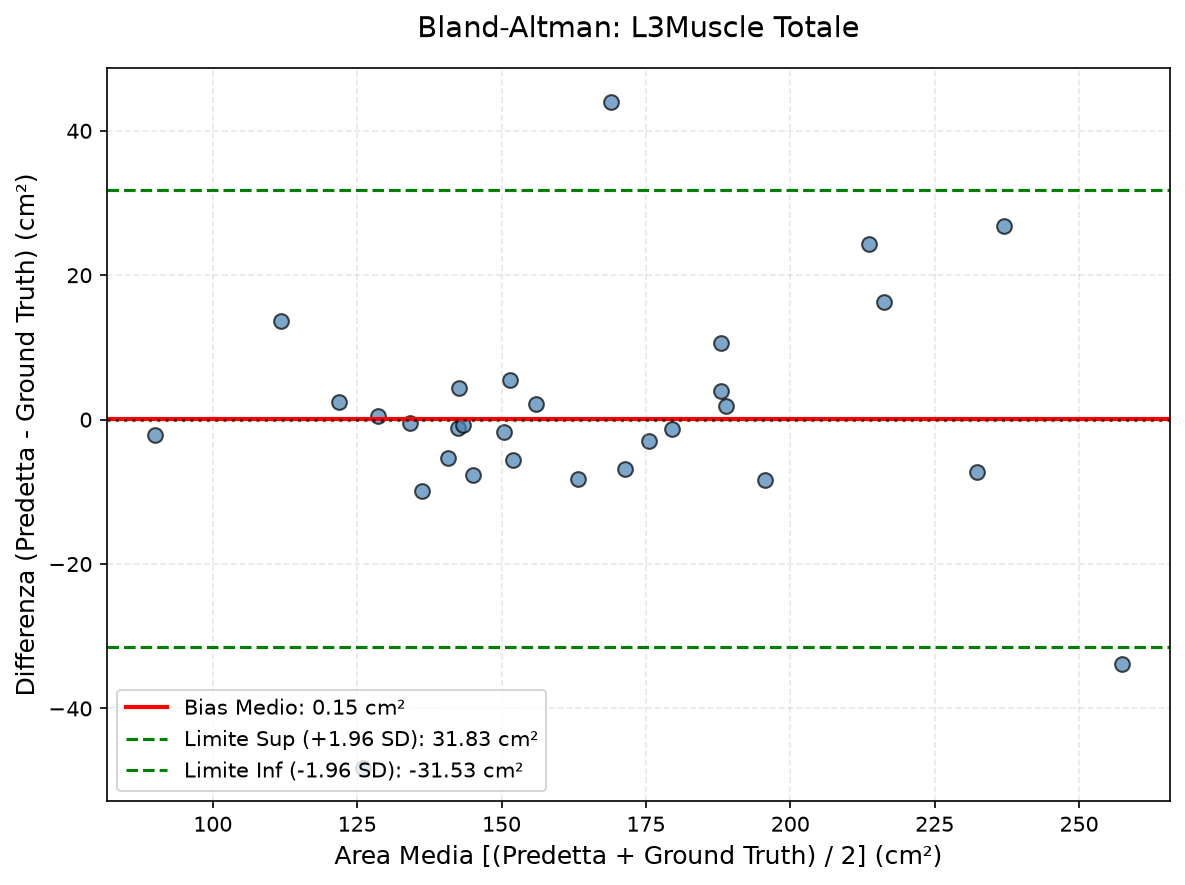

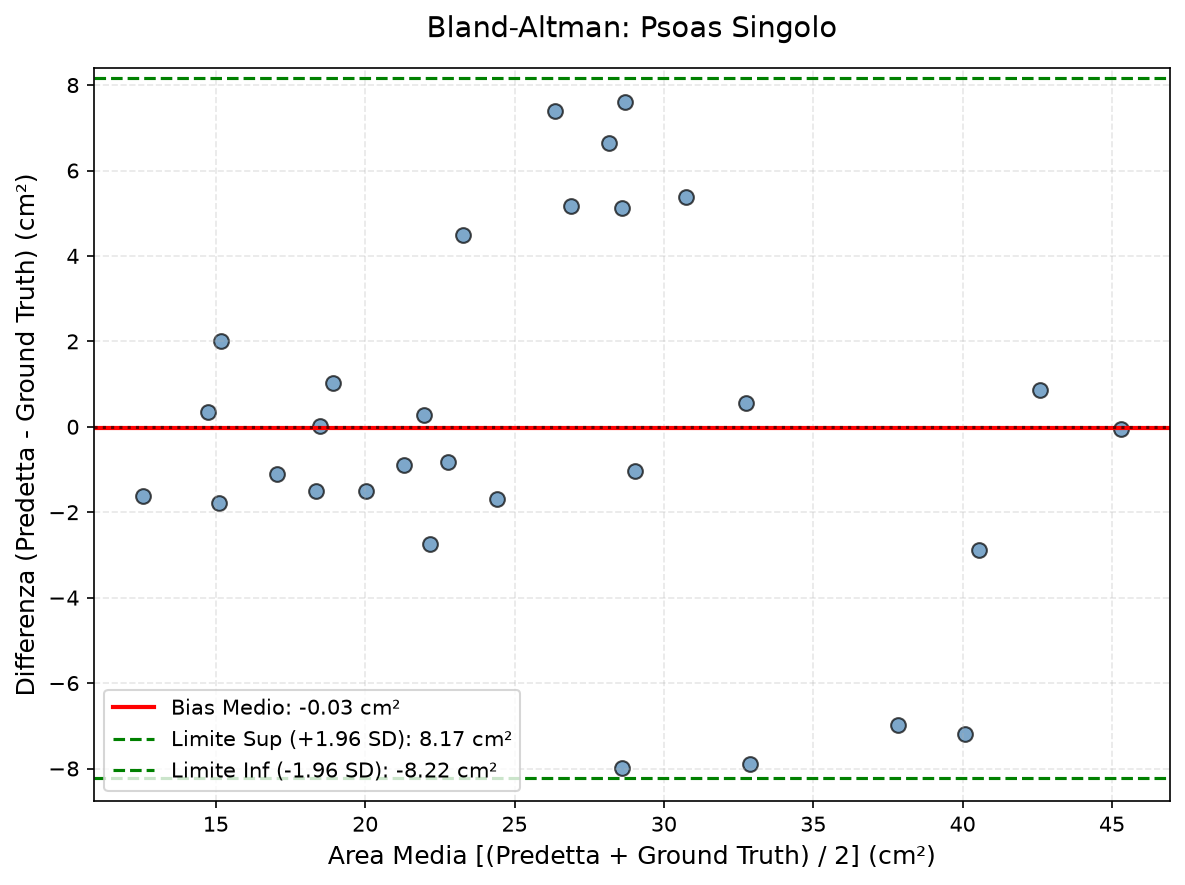

In [17]:
import numpy as np
import nibabel as nib
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

print("\n==================================================")
print(" ANALISI ERRORI SULLE MISURE DERIVATE (AREE IN CM²)")
print("==================================================")

true_l3Muscle_list, pred_l3Muscle_list = [], []
true_psoas_list, pred_psoas_list = [], []
patient_ids = []

TARGET_SIZE = (256, 256)
HU_MIN, HU_MAX = -30.0, 150.0

# Rieseguiamo rapidamente l'inferenza per tracciare con precisione le metriche derivate
for ct_path, mask_path in zip(external_ct_files, external_mask_files):
    patient_ids.append(ct_path.name)
    
    nii_ct = nib.load(ct_path)
    nii_mask = nib.load(mask_path)
    
    original_data = np.squeeze(nii_ct.get_fdata())
    true_mask = np.squeeze(nii_mask.get_fdata())
    original_shape = original_data.shape
    
    # Estrazione spaziature e calcolo area singolo pixel
    spacing_x_mm, spacing_y_mm = nii_ct.header.get_zooms()[:2]
    pixel_area_cm2 = (spacing_x_mm * spacing_y_mm) / 100.0
    
    # Preprocessing e Inferenza (identico alla tua pipeline)
    img_np = np.clip(original_data, HU_MIN, HU_MAX)
    img_np = (img_np - HU_MIN) / (HU_MAX - HU_MIN)
    img_tensor = tf.expand_dims(tf.convert_to_tensor(img_np, dtype=tf.float32), axis=-1)
    img_resized = tf.image.resize(img_tensor, TARGET_SIZE, method='bilinear').numpy()
    
    preds = model.predict(np.expand_dims(img_resized, axis=0), verbose=0)
    pred_mask_256 = np.argmax(preds, axis=-1)[0]
    
    pred_mask = tf.image.resize(
        np.expand_dims(pred_mask_256, axis=-1),
        original_shape[:2], 
        method='nearest'
    ).numpy().squeeze()
    
    # 1. Calcolo Aree (Ground Truth)
    t_l3Muscle = np.sum((true_mask == 1) | (true_mask == 2)) * pixel_area_cm2
    t_psoas = np.sum(true_mask == 2) * pixel_area_cm2
    
    # 2. Calcolo Aree (Predizione AI)
    p_l3Muscle = np.sum((pred_mask == 1) | (pred_mask == 2)) * pixel_area_cm2
    p_psoas = np.sum(pred_mask == 2) * pixel_area_cm2
    
    true_l3Muscle_list.append(t_l3Muscle)
    pred_l3Muscle_list.append(p_l3Muscle)
    true_psoas_list.append(t_psoas)
    pred_psoas_list.append(p_psoas)

# Conversioni in array per calcolo vettoriale
true_l3Muscle = np.array(true_l3Muscle_list)
pred_l3Muscle = np.array(pred_l3Muscle_list)
true_psoas = np.array(true_psoas_list)
pred_psoas = np.array(pred_psoas_list)

# Calcolo Errori
def get_error_stats(t_arr, p_arr):
    abs_err = np.abs(t_arr - p_arr)
    # Evita divisioni per zero usando 1e-5 se un'area true dovesse risultare 0
    rel_err = (abs_err / np.where(t_arr == 0, 1e-5, t_arr)) * 100 
    return np.mean(abs_err), np.std(abs_err), np.mean(rel_err), np.std(rel_err)

abs_mean_l3, abs_std_l3, rel_mean_l3, rel_std_l3 = get_error_stats(true_l3Muscle, pred_l3Muscle)
abs_mean_ps, abs_std_ps, rel_mean_ps, rel_std_ps = get_error_stats(true_psoas, pred_psoas)

print(f"L3Muscle (Classi 1+2) -> Errore Assoluto: {abs_mean_l3:.2f} ± {abs_std_l3:.2f} cm² | Errore Relativo: {rel_mean_l3:.2f}% ± {rel_std_l3:.2f}%")
print(f"L3 Psoas (Classe 2) -> Errore Assoluto: {abs_mean_ps:.2f} ± {abs_std_ps:.2f} cm² | Errore Relativo: {rel_mean_ps:.2f}% ± {rel_std_ps:.2f}%")

# --- FUNZIONE BLAND-ALTMAN ---
def plot_bland_altman(true_vals, pred_vals, title_name):
    means = (true_vals + pred_vals) / 2.0
    diffs = pred_vals - true_vals  # Valori > 0 = Sovrastima AI; Valori < 0 = Sottostima AI
    
    bias = np.mean(diffs)
    std_diff = np.std(diffs)
    loa_upper = bias + 1.96 * std_diff
    loa_lower = bias - 1.96 * std_diff
    
    plt.figure(figsize=(8, 6), dpi=150)
    plt.scatter(means, diffs, alpha=0.7, color='steelblue', edgecolor='black', s=50)
    
    plt.axhline(bias, color='red', linestyle='-', linewidth=2, label=f'Bias Medio: {bias:.2f} cm²')
    plt.axhline(loa_upper, color='green', linestyle='--', linewidth=1.5, label=f'Limite Sup (+1.96 SD): {loa_upper:.2f} cm²')
    plt.axhline(loa_lower, color='green', linestyle='--', linewidth=1.5, label=f'Limite Inf (-1.96 SD): {loa_lower:.2f} cm²')
    plt.axhline(0, color='black', linestyle=':', alpha=0.6) # Linea di zero errore
    
    plt.title(f'Bland-Altman: {title_name}', fontsize=14, pad=15)
    plt.xlabel('Area Media [(Predetta + Ground Truth) / 2] (cm²)', fontsize=12)
    plt.ylabel('Differenza (Predetta - Ground Truth) (cm²)', fontsize=12)
    
    # Changed loc to 'lower left'
    plt.legend(loc='lower left', frameon=True, fontsize=10)
    
    plt.grid(True, alpha=0.3, linestyle='--')
    plt.tight_layout()
    # plt.savefig(f"BlandAltman_{title_name.replace(' ', '')}.png", bbox_inches='tight', facecolor='white')
    plt.show()

# Esecuzione dei plot
plot_bland_altman(true_l3Muscle, pred_l3Muscle, "L3Muscle Totale")
plot_bland_altman(true_psoas, pred_psoas, "Psoas Singolo")

# Esportazione DataFrame opzionale
df_errors = pd.DataFrame({
    'Patient_ID': patient_ids,
    'True_L3Muscle_cm2': true_l3Muscle,
    'Pred_L3Muscle_cm2': pred_l3Muscle,
    'Diff_L3Muscle_cm2': pred_l3Muscle - true_l3Muscle,
    'True_Psoas_cm2': true_psoas,
    'Pred_Psoas_cm2': pred_psoas,
    'Diff_Psoas_cm2': pred_psoas - true_psoas
})
